# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [2]:
# Import necessary libraries
import random
import pathlib
from collections import Counter
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print("TensorFlow version:", tf.__version__)
print("GPUs visible:", tf.config.list_physical_devices('GPU'))

I0000 00:00:1792963730.842967    1344 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792963733.990863    1344 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792963739.749306    1344 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0
GPUs visible: []


E0000 00:00:1792963742.029279    1344 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792963742.029663    3988 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792963742.075744    1344 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


                     n_images   pct
Plastic                   921  19.4
Metal                     790  16.6
Paper                     500  10.5
Miscellaneous Trash       495  10.4
Cardboard                 461   9.7
Vegetation                436   9.2
Glass                     420   8.8
Food Organics             411   8.6
Textile Trash             318   6.7

Total images: 4752


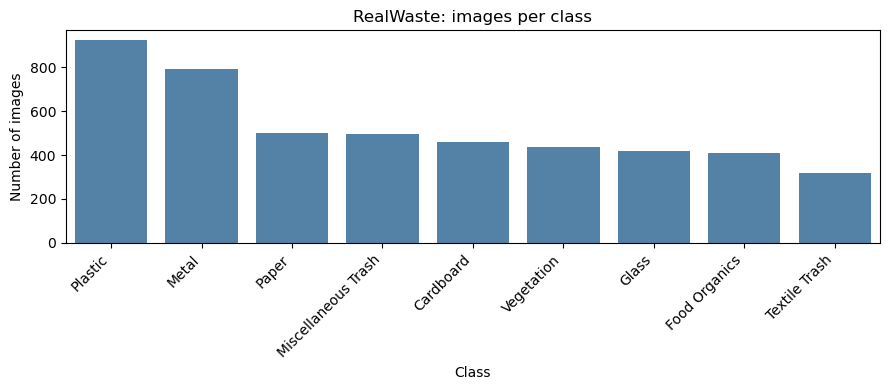

In [3]:
# - Dataset structure
# - Distribution of waste categories

data_dir = pathlib.Path('RealWaste')

# Count images per class folder
class_counts = {}
for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        n = len(list(folder.glob('*.jpg'))) + len(list(folder.glob('*.png')))
        class_counts[folder.name] = n

counts_df = (pd.Series(class_counts, name='n_images')
               .sort_values(ascending=False)
               .to_frame())
counts_df['pct'] = (counts_df['n_images'] / counts_df['n_images'].sum() * 100).round(1)
print(counts_df)
print("\nTotal images:", counts_df['n_images'].sum())

# Visualize the distribution
plt.figure(figsize=(9, 4))
sns.barplot(x=counts_df.index, y=counts_df['n_images'], color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.title('RealWaste: images per class')
plt.ylabel('Number of images')
plt.xlabel('Class')
plt.tight_layout()
plt.show()

In [4]:
# - Image characteristics (resolution, quality, background)

# --- Resolution / mode / format across ALL images ---
records = []
for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        for img_path in folder.glob('*'):
            if img_path.suffix.lower() in ('.jpg', '.jpeg', '.png'):
                with Image.open(img_path) as im:
                    records.append({
                        'class': folder.name,
                        'width': im.size[0],
                        'height': im.size[1],
                        'mode': im.mode,
                        'format': im.format,
                        'file_kb': img_path.stat().st_size / 1024,
                    })

img_df = pd.DataFrame(records)
print(img_df[['width', 'height', 'file_kb']].describe().round(1))
print("\nUnique (width, height) pairs:", img_df.groupby(['width', 'height']).ngroups)
print("\nColor modes:\n", img_df['mode'].value_counts())
print("\nFormats:\n", img_df['format'].value_counts())
print("\nMean file size (KB) by class:\n", img_df.groupby('class')['file_kb'].mean().round(1))


        width  height  file_kb
count  4752.0  4752.0   4752.0
mean    524.0   524.0    141.5
std       0.0     0.0     39.7
min     524.0   524.0     47.7
25%     524.0   524.0    110.9
50%     524.0   524.0    133.8
75%     524.0   524.0    174.0
max     524.0   524.0    242.8

Unique (width, height) pairs: 1

Color modes:
 mode
RGB    4752
Name: count, dtype: int64

Formats:
 format
JPEG    4752
Name: count, dtype: int64

Mean file size (KB) by class:
 class
Cardboard              120.2
Food Organics          181.8
Glass                  115.3
Metal                  122.5
Miscellaneous Trash    145.1
Paper                  128.9
Plastic                140.1
Textile Trash          136.3
Vegetation             202.3
Name: file_kb, dtype: float64


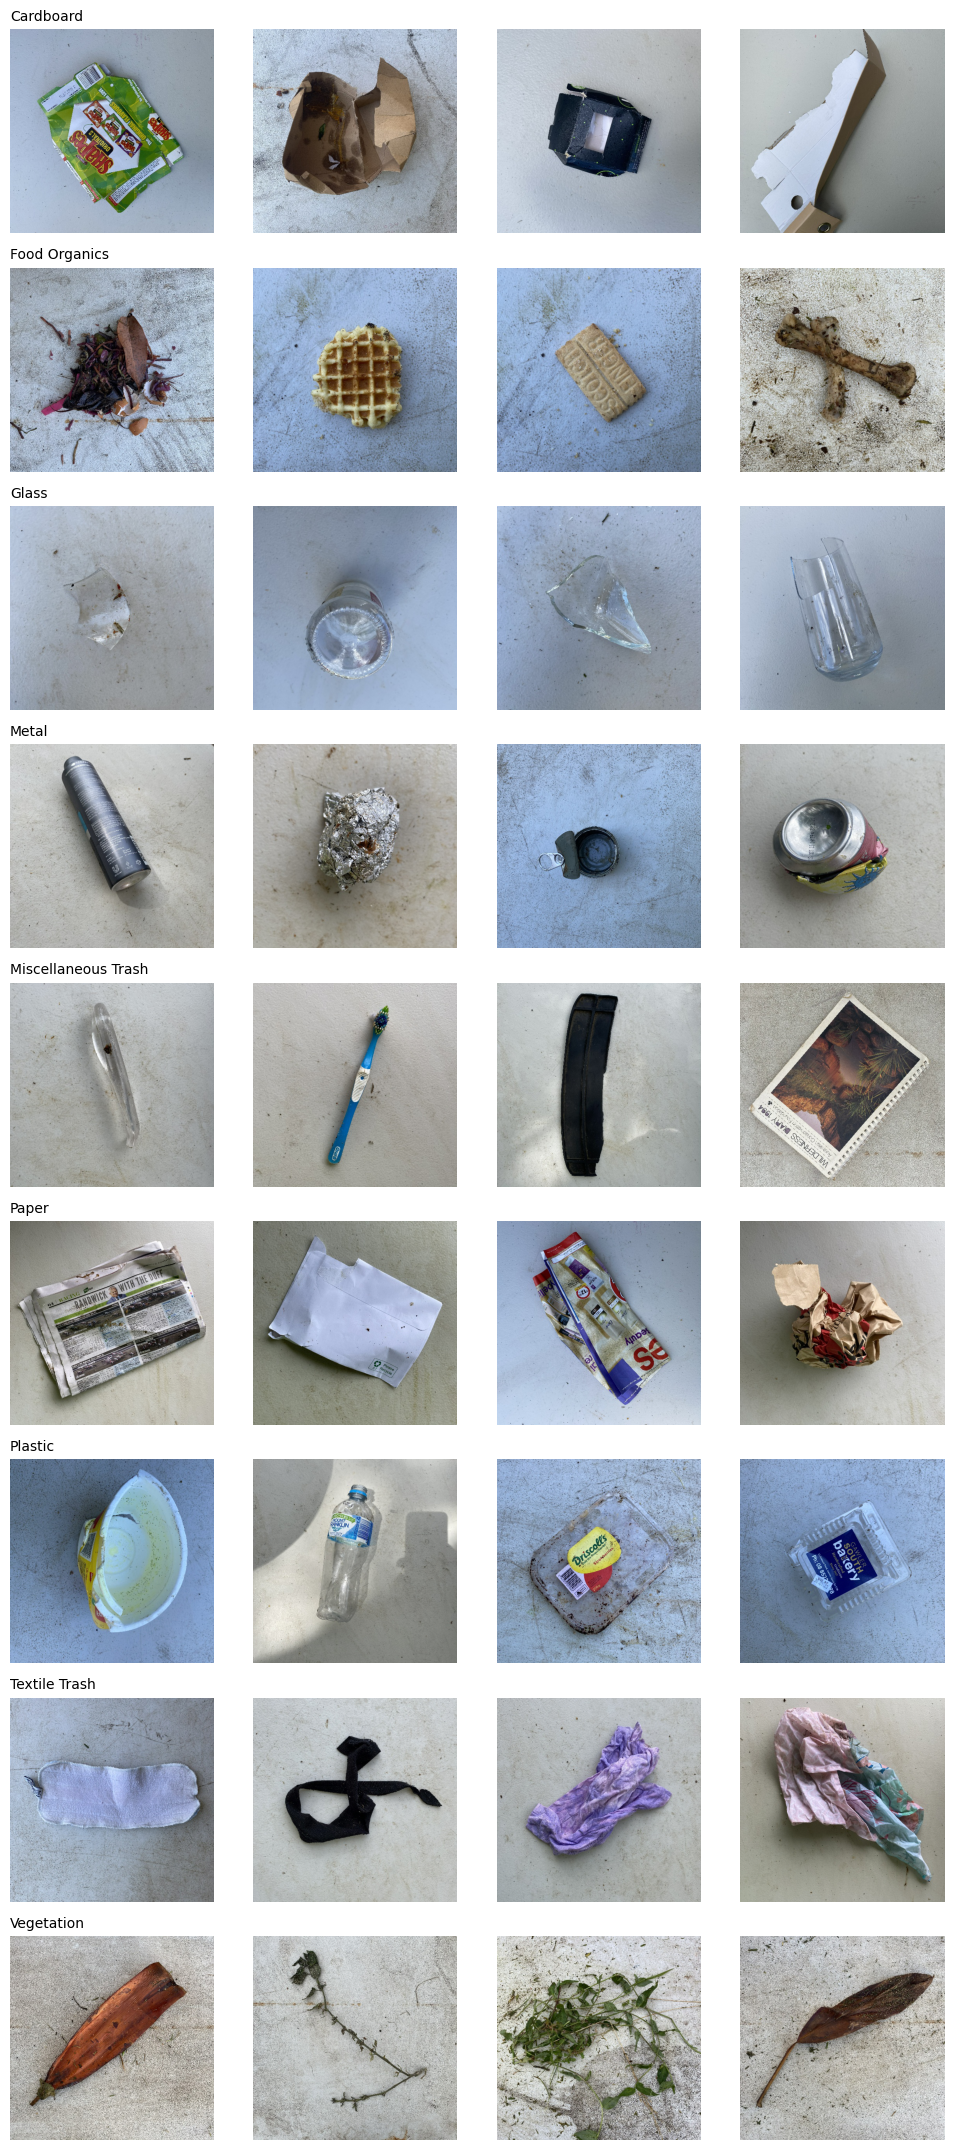

In [5]:
# --- Sample grid: 4 random images per class ---
classes = sorted(img_df['class'].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.4 * len(classes)))

for row, cls in enumerate(classes):
    paths = random.sample(list((data_dir / cls).glob('*.jpg')), 4)
    for col, p in enumerate(paths):
        axes[row, col].imshow(Image.open(p))
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_title(cls, loc='left', fontsize=10)

plt.tight_layout()
plt.show()

                              R           G           B  blue_minus_red
class                                                                  
Cardboard            159.899994  170.899994  183.100006       23.100000
Food Organics        162.800003  172.699997  183.600006       20.799999
Glass                159.100006  169.899994  184.000000       25.000000
Metal                171.199997  173.699997  172.399994        1.200000
Miscellaneous Trash  173.100006  176.699997  177.000000        3.900000
Paper                158.899994  162.399994  160.199997        1.300000
Plastic              155.899994  167.199997  178.800003       22.900000
Textile Trash        178.699997  181.100006  178.100006       -0.700000
Vegetation           183.500000  184.199997  179.000000       -4.600000


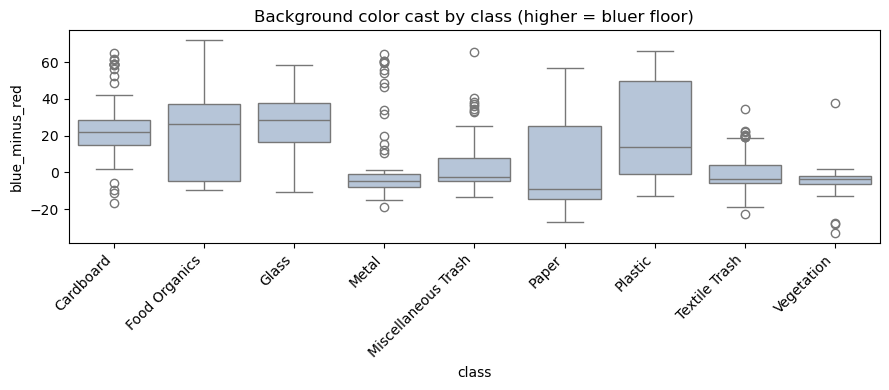

In [6]:
# --- Does background color differ by class? (border pixels only) ---
rows = []
for cls in sorted(img_df['class'].unique()):
    paths = random.sample(list((data_dir / cls).glob('*.jpg')), 100)
    for p in paths:
        arr = np.asarray(Image.open(p), dtype=np.float32)
        border = np.concatenate([
            arr[:40].reshape(-1, 3), arr[-40:].reshape(-1, 3),
            arr[:, :40].reshape(-1, 3), arr[:, -40:].reshape(-1, 3),
        ])
        r, g, b = border.mean(axis=0)
        rows.append({'class': cls, 'R': r, 'G': g, 'B': b, 'blue_minus_red': b - r})

bg_df = pd.DataFrame(rows)
print(bg_df.groupby('class')[['R', 'G', 'B', 'blue_minus_red']].mean().round(1))

plt.figure(figsize=(9, 4))
sns.boxplot(data=bg_df, x='class', y='blue_minus_red', color='lightsteelblue')
plt.xticks(rotation=45, ha='right')
plt.title('Background color cast by class (higher = bluer floor)')
plt.tight_layout()
plt.show()

#### Findings: RealWaste image data

**Structure and balance.** 4,752 images in 9 classes (the assignment prose mentions 8 categories, but the dataset and notebook have 9). Class sizes range from 318 (Textile Trash, 6.7%) to 921 (Plastic, 19.4%), roughly a 2.9:1 imbalance. A model that always predicts "Plastic" would score ~19.4%, which is the baseline to beat. Since overall accuracy can hide weak performance on small classes, evaluation will use per-class metrics and a confusion matrix, and training will use class weights.

**Image characteristics.** All images are 524×524 RGB JPEGs, so resizing to 224×224 is a uniform downscale with no aspect-ratio distortion. Each photo shows one item, top-down, on a concrete surface. Mean file size differs by class (Glass ≈115 KB vs. Vegetation ≈202 KB), reflecting differences in texture and detail.

**Potential bias: background shortcut.** Mean floor color (border pixels, 100 images per class) splits into two groups, measured as blue minus red: a bluer group (Cardboard +23, Food Organics +21, Glass +25, Plastic +23) and a neutral group (Metal +1, Miscellaneous +4, Paper +1, Textile −1, Vegetation −5). A CNN could use floor color as a partial cue, which would inflate accuracy relative to real photos with varied backgrounds. This is a sample-based measurement and only separates the two groups, not classes within a group. Mitigation: color and brightness augmentation. Limitation: test accuracy here likely overstates performance on residents' phone photos.

**Expected challenges (hypotheses to check against the confusion matrix).** Transparent items (Glass vs. clear Plastic) have low contrast; Paper vs. Cardboard overlap on printed or crumpled packaging; Miscellaneous Trash is a catch-all with no coherent visual identity, so some errors will reflect label ambiguity rather than model failure.

### 1.2 Explore Text Datasets

In [7]:
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories

# --- Waste descriptions ---
desc_df = pd.read_csv('waste_descriptions.csv')
print("Shape:", desc_df.shape)
print("Columns:", desc_df.columns.tolist())
print("\nMissing values:\n", desc_df.isna().sum())
print("\nExact duplicate rows:", desc_df.duplicated().sum())
print("\nFirst 8 rows:")
print(desc_df.head(8).to_string())

Shape: (5000, 5)
Columns: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']

Missing values:
 description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0
dtype: int64

Exact duplicate rows: 7

First 8 rows:
                                              description       category                                    disposal_instruction                                                                                      common_confusion                                                   material_composition
0                                soiled silver tablecloth  Textile Trash       Look for textile recycling programs in your area.                                                                                                   NaN      Fabric made from natural or synthetic fibers, may include blends.
1                             folded glass bottle leaking 

category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64

Categories in text data: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
In images but not text: set()
In text but not images: set()


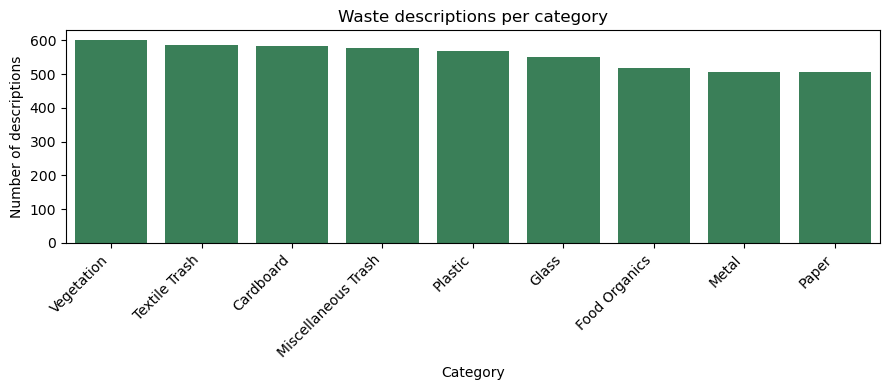

In [8]:
# --- Category distribution ---
cat_counts = desc_df['category'].value_counts()
print(cat_counts)
print("\nCategories in text data:", sorted(desc_df['category'].unique()))

image_classes = {f.name for f in data_dir.iterdir() if f.is_dir()}
print("In images but not text:", image_classes - set(desc_df['category']))
print("In text but not images:", set(desc_df['category']) - image_classes)

plt.figure(figsize=(9, 4))
sns.barplot(x=cat_counts.index, y=cat_counts.values, color='seagreen')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Category')
plt.ylabel('Number of descriptions')
plt.title('Waste descriptions per category')
plt.tight_layout()
plt.show()

In [9]:
# --- Structure: length, vocabulary, duplicates, label conflicts ---
desc_df['n_words'] = desc_df['description'].str.split().str.len()
print(desc_df['n_words'].describe().round(1))

all_words = desc_df['description'].str.lower().str.split().explode()
print("\nTotal tokens:", len(all_words), "| Unique words:", all_words.nunique())
print("Top 15 words:\n", all_words.value_counts().head(15))

n_unique_desc = desc_df['description'].nunique()
print(f"\nUnique descriptions: {n_unique_desc} of {len(desc_df)}")

# Same description appearing with more than one label?
label_conflicts = desc_df.groupby('description')['category'].nunique()
conflicts = label_conflicts[label_conflicts > 1]
print("Descriptions with conflicting labels:", len(conflicts))
print(desc_df[desc_df['description'].isin(conflicts.index)]
      .sort_values('description')[['description', 'category']].head(12).to_string())

count    5000.0
mean        4.9
std         1.5
min         1.0
25%         4.0
50%         5.0
75%         6.0
max        10.0
Name: n_words, dtype: float64

Total tokens: 24270 | Unique words: 305
Top 15 words:
 description
with        727
glass       424
empty       348
bottle      342
paper       316
food        316
box         313
residue     309
plastic     251
brand       247
metal       241
dry         211
new         196
crumpled    189
soiled      189
Name: count, dtype: int64

Unique descriptions: 4939 of 5000
Descriptions with conflicting labels: 0
Empty DataFrame
Columns: [description, category]
Index: []


In [10]:
# --- How many distinct disposal instructions per category? (RAG source material) ---
print(desc_df.groupby('category')['disposal_instruction'].nunique())
print()
for cat in sorted(desc_df['category'].unique()):
    print(cat)
    for ins in desc_df.loc[desc_df['category'] == cat, 'disposal_instruction'].unique():
        print("   -", ins)

category
Cardboard              5
Food Organics          5
Glass                  5
Metal                  5
Miscellaneous Trash    5
Paper                  5
Plastic                5
Textile Trash          5
Vegetation             5
Name: disposal_instruction, dtype: int64

Cardboard
   - If contaminated with food, tear off contaminated parts.
   - Flatten boxes before placing in cardboard recycling.
   - For waxed cardboard, check local guidelines as it may not be recyclable.
   - Break down large boxes to save space.
   - Remove any plastic, styrofoam, or metal parts before recycling.
Food Organics
   - If no compost available, place in general waste.
   - Keep separate from recyclable materials.
   - Use compostable bags for collection if required.
   - Can be used in home composting system (except meat and dairy in some cases).
   - Place in organic waste or compost bin.
Glass
   - Remove caps, lids, and corks before recycling.
   - Rinse container before recycling.
   - Place in 

In [ ]:
# --- How often does a description contain its own category's name? ---
own_name = desc_df.apply(lambda r: r['category'].split()[0].lower() in r['description'].lower(), axis=1)
print(own_name.groupby(desc_df['category']).mean().round(2))
print("Overall:", round(own_name.mean(), 2))

category
Cardboard              0.18
Food Organics          0.15
Glass                  0.69
Metal                  0.42
Miscellaneous Trash    0.00
Paper                  0.61
Plastic                0.37
Textile Trash          0.00
Vegetation             0.00
dtype: float64
Overall: 0.26


#### Findings: waste description data

- **Size and labels.** 5,000 descriptions with 5 columns. The 9 categories match the 9 image classes exactly, so no label mapping is needed between the image and text models.
- **Balance.** 506–600 descriptions per category (about 1.2:1), much more balanced than the images, so accuracy is a fair headline metric (per-class results still reported).
- **Language.** Descriptions are very short and formulaic: mean 4.9 words (max 10) and only 305 distinct words across 24,270 tokens. This strongly suggests template-generated text (condition + adjective + object), not real resident writing. A high score is expected and reflects an easy task, not necessarily a robust model.
- **Duplicates and conflicts.** 4,939 of 5,000 descriptions are unique (61 repeats), and no description has two different labels. I will deduplicate on `description` before splitting so repeats cannot land in both train and test.
- **Keyword leakage.** Material words ("glass" 424, "paper" 316, "plastic" 251, "metal" 241) are among the most frequent tokens. Overall 26% of descriptions contain their literal category name, but this varies widely: Glass 69%, Paper 61%, Metal 42%, Plastic 37%, Cardboard 18%, Food Organics 15%, and 0% for Textile Trash, Miscellaneous Trash, and Vegetation, whose label words never appear. This understates the issue: object words such as "bottle" and "box" are likely also category-specific, so expect near-ceiling accuracy.
- **Columns.** `disposal_instruction` has only 5 distinct values per category (45 total), so it is derived from the label and is excluded from classifier input to avoid leakage; it feeds the RAG knowledge base in Part 4. `common_confusion` is blank in 2,504 rows (50%), meaning "no confusion case", not missing data.

In [12]:
# - Load waste_policy_documents.json
# - Understand document organization and language

# --- Policy documents ---
with open('waste_policy_documents.json') as f:
    policy_raw = json.load(f)
print("JSON root type:", type(policy_raw))
if isinstance(policy_raw, dict):
    print("Top-level keys:", list(policy_raw.keys())[:20])
else:
    print("Number of entries:", len(policy_raw))
    print("First entry:\n", json.dumps(policy_raw[0], indent=2)[:1500])

JSON root type: <class 'list'>
Number of entries: 14
First entry:
 {
  "policy_id": 1,
  "policy_type": "Textile Trash Recycling Guidelines",
  "categories_covered": [
    "Textile Trash"
  ],
  "effective_date": "2023-11-04",
  "document_text": "TEXTILE RECYCLING GUIDELINES\n\nAcceptable Items:\n- Clean clothing (all conditions)\n- Towels, sheets, and linens\n- Fabric scraps\n- Curtains and cloth napkins\n- Handbags and backpacks made of fabric\n- Soft toys and stuffed animals\n\nNon-Acceptable Items:\n- Wet or moldy textiles\n- Heavily soiled items\n- Carpets and rugs\n- Footwear\n- Items with significant non-textile parts\n\nCollection Method:\nPlace items in dedicated textile recycling bins or donate to local thrift stores.\n\nPreparation Instructions:\n- Ensure all items are clean and dry\n- Remove non-textile components when possible\n- Bag similar items together\n\nBenefits:\nTextile recycling conserves resources and reduces landfill waste.",
  "jurisdiction": "Metro City"
}


In [13]:
# --- Overview table of every policy document ---
policy_df = pd.DataFrame(policy_raw)
policy_df['n_chars'] = policy_df['document_text'].str.len()
policy_df['n_words'] = policy_df['document_text'].str.split().str.len()
policy_df['categories_str'] = policy_df['categories_covered'].apply(lambda c: ', '.join(c))

print(policy_df[['policy_id', 'policy_type', 'categories_str',
                 'effective_date', 'jurisdiction', 'n_words']].to_string())
print("\nJurisdictions:", policy_df['jurisdiction'].unique())
print("Word count range:", policy_df['n_words'].min(), "-", policy_df['n_words'].max())

    policy_id                               policy_type                                          categories_str effective_date jurisdiction  n_words
0           1        Textile Trash Recycling Guidelines                                           Textile Trash     2023-11-04   Metro City      104
1           2                Glass Recycling Guidelines                                                   Glass     2023-01-24   Metro City       86
2           3        Food Organics Recycling Guidelines                                           Food Organics     2023-05-08   Metro City       98
3           4              Plastic Recycling Guidelines                                                 Plastic     2023-04-05   Metro City       94
4           5           Vegetation Recycling Guidelines                                              Vegetation     2023-12-04   Metro City       94
5           6            Cardboard Recycling Guidelines                                               Card

In [14]:
# --- Which of the 9 categories are covered, and by how many documents? ---
coverage = Counter(cat for cats in policy_df['categories_covered'] for cat in cats)
all_cats = sorted(desc_df['category'].unique())

for cat in all_cats:
    print(f"{cat:22s} covered by {coverage.get(cat, 0)} document(s)")

print("\nCategories named in policies but not in the 9 image classes:",
      set(coverage) - set(all_cats))

Cardboard              covered by 3 document(s)
Food Organics          covered by 2 document(s)
Glass                  covered by 3 document(s)
Metal                  covered by 4 document(s)
Miscellaneous Trash    covered by 4 document(s)
Paper                  covered by 1 document(s)
Plastic                covered by 3 document(s)
Textile Trash          covered by 3 document(s)
Vegetation             covered by 4 document(s)

Categories named in policies but not in the 9 image classes: set()


In [15]:
# --- Section headers used across documents (informs chunking) ---
import re
header_counts = Counter()
for text in policy_df['document_text']:
    for line in text.split('\n'):
        line = line.strip()
        if line.endswith(':') and not line.startswith('-'):
            header_counts[line] += 1

print(header_counts.most_common(15))

# Read one non-material document in full (pick one that isn't a single-category guideline)
non_material = policy_df[policy_df['categories_covered'].str.len() != 1]
print("\nDocuments covering 0 or 2+ categories:", len(non_material))
if len(non_material):
    row = non_material.iloc[0]
    print("\n---", row['policy_type'], "---\n")
    print(row['document_text'])

[('Benefits:', 9), ('Acceptable Items:', 8), ('Non-Acceptable Items:', 8), ('Collection Method:', 8), ('Preparation Instructions:', 8), ('GENERAL REQUIREMENTS:', 5), ('MISCELLANEOUS TRASH GUIDELINES:', 3), ('VEGETATION GUIDELINES:', 3), ('METAL GUIDELINES:', 3), ('PLASTIC GUIDELINES:', 2), ('GLASS GUIDELINES:', 2), ('CARDBOARD GUIDELINES:', 2), ('TEXTILE TRASH GUIDELINES:', 2), ('Items That Cannot Be Recycled:', 1), ('Special Handling Items:', 1)]

Documents covering 0 or 2+ categories: 5

--- Municipal Waste Guidelines ---

MUNICIPAL WASTE GUIDELINES

GENERAL REQUIREMENTS:
- Place recyclables in appropriate bins
- Ensure materials are clean and properly sorted
- Follow collection schedules
- Keep hazardous materials separate


PLASTIC GUIDELINES:
- PET bottles and containers (code #1)
- HDPE containers (code #2)
- PP containers (code #5)
- Clean plastic packaging
- Plastic bags and film

MISCELLANEOUS TRASH GUIDELINES:
- Multi-material items
- Heavily soiled packaging
- Certain plasti

#### Findings: policy documents

- **Corpus.** 14 JSON documents, all for "Metro City", all effective during 2023 (Jan–Dec), each 86–146 words.
- **Types.** Nine are single-category guidelines (one per category). Five are multi-category (Municipal Waste Guidelines, Residential Recycling Rules, Commercial Recycling Standards, Multi-Unit Building Guidelines, Community Recycling Program) covering 3–5 categories each via a `categories_covered` list.
- **Uneven coverage.** Paper appears in 1 document, Food Organics in 2, Cardboard/Glass/Plastic/Textile in 3, and Metal/Miscellaneous/Vegetation in 4. Retrieval for Paper has little to draw on; for others it must choose among several documents.
- **Structure and chunking plan.** Single-category documents use a fixed template (Acceptable Items, Non-Acceptable Items, Collection Method, Preparation Instructions, Benefits). Multi-category documents use per-category headers (e.g., "PLASTIC GUIDELINES:") plus "GENERAL REQUIREMENTS:". Documents are so short that fixed-size splitting would cut through lists, so I will chunk by section/category block and attach metadata (policy_id, policy_type, category, effective_date) so retrieval can be filtered by category.
- **Consistency issues to handle in Part 4.** (1) The Textile guideline lists "Clean clothing (all conditions)" as acceptable but "Heavily soiled items" as not acceptable, while the descriptions data labels soiled textiles as Textile Trash with the advice to find textile recycling programs. (2) The Municipal Waste Guidelines list "Plastic bags and film" under plastic guidelines, while the description data warns plastic bags often cannot go in general recycling. Proposed rule (revise if I decide otherwise): when documents conflict, prefer the category-specific document, and evaluate generated instructions against it.

### 1.3 Create Data Pipelines

In [ ]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('RealWaste')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=True)

held_out_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=True)

# Iterate the held-out 20% exactly ONCE so its contents are frozen, then split that
# fixed list into test and validation. (take()/skip() on the live dataset reshuffles
# on every pass and can leak images between the two halves.)
held_out = list(held_out_ds)
split_at = len(held_out) // 2

def batches_to_ds(batches):
    x = tf.concat([b[0] for b in batches], axis=0)
    y = tf.concat([b[1] for b in batches], axis=0)
    return tf.data.Dataset.from_tensor_slices((x, y)).batch(BATCH_SIZE)

test_dataset = batches_to_ds(held_out[:split_at])
validation_ds = batches_to_ds(held_out[split_at:])

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

del held_out, held_out_ds   # free memory; the datasets above hold their own copies

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [17]:
def class_dist(ds):
    counts = np.zeros(num_classes, dtype=int)
    for _, y in ds:
        counts += y.numpy().sum(axis=0).astype(int)
    return counts

split_dist = pd.DataFrame({'train': class_dist(train_ds),
                           'val': class_dist(validation_ds),
                           'test': class_dist(test_dataset)}, index=class_names)
split_dist['train_pct'] = (split_dist['train'] / split_dist['train'].sum() * 100).round(1)
split_dist['val_pct'] = (split_dist['val'] / split_dist['val'].sum() * 100).round(1)
split_dist['test_pct'] = (split_dist['test'] / split_dist['test'].sum() * 100).round(1)
print(split_dist)

                     train  val  test  train_pct  val_pct  test_pct
Cardboard              387   31    43       10.2      6.6       9.0
Food Organics          327   47    37        8.6     10.0       7.7
Glass                  342   39    39        9.0      8.3       8.1
Metal                  617   81    92       16.2     17.2      19.2
Miscellaneous Trash    403   36    56       10.6      7.7      11.7
Paper                  381   59    60       10.0     12.6      12.5
Plastic                742   97    82       19.5     20.6      17.1
Textile Trash          243   36    39        6.4      7.7       8.1
Vegetation             360   44    32        9.5      9.4       6.7


**Split design.** Images are split 80% train / ~10% validation / ~10% test (3,802 / 470 / 480). Both loaders use `shuffle=True` with `seed=42`: Keras shuffles the file list globally *before* slicing off the held-out 20%, so the split is random across classes and reproducible. (With `shuffle=False` the list stays in folder order, and the held-out 20% would be only the last classes alphabetically.) The held-out portion is iterated once and frozen in memory, then divided into validation and test, so no image can appear in both. **Limitation:** the split is random rather than stratified, so class shares drift by a few points in the smaller sets (e.g., Cardboard is 10.2% of train but 6.6% of validation; Vegetation is 9.5% of train but 6.7% of test). Every class is represented, but with only 32–92 test images per class, per-class metrics will be noisy: one error moves a small class's recall by 1–3 points.

In [21]:
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Keep only what the classifier may see: the description and its label.
# disposal_instruction / material_composition are derived from the label (leakage).
text_df = desc_df[['description', 'category']].copy()

# 1) Minimal cleaning. The text is already tidy (305 distinct words), so we only
#    normalize case and whitespace. We do NOT remove stop words or stem: with ~5-word
#    descriptions every token carries signal (e.g., "with residue", "empty").
text_df['text'] = (text_df['description'].str.lower()
                   .str.replace(r'\s+', ' ', regex=True).str.strip())

# 2) Deduplicate AFTER normalizing, so case variants count as duplicates too
before = len(text_df)
text_df = text_df.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Dropped {before - len(text_df)} duplicate descriptions -> {len(text_df)} rows")

# 3) Reuse the image model's class order so label ids match across both classifiers
label_to_id = {name: i for i, name in enumerate(class_names)}
text_df['label'] = text_df['category'].map(label_to_id)
assert text_df['label'].notna().all()

# 4) Stratified 80/10/10 split (stratified because the categories are not perfectly balanced)
train_text, temp_text = train_test_split(
    text_df, test_size=0.2, stratify=text_df['label'], random_state=42)
val_text, test_text = train_test_split(
    temp_text, test_size=0.5, stratify=temp_text['label'], random_state=42)

# 5) Sanity checks: sizes, class shares, and zero text shared across splits
print({n: len(d) for n, d in [('train', train_text), ('val', val_text), ('test', test_text)]})
split_cat = pd.DataFrame({'train': train_text['category'].value_counts(normalize=True),
                          'val': val_text['category'].value_counts(normalize=True),
                          'test': test_text['category'].value_counts(normalize=True)}).mul(100).round(1)
print(split_cat)
shared = set(train_text['text']) & (set(val_text['text']) | set(test_text['text']))
print("Texts shared between train and held-out splits:", len(shared))

# 6) Features: TF-IDF over unigrams + bigrams (bigrams capture pairs like "glass bottle").
# Fit on TRAIN only, then apply to val/test, so no vocabulary information leaks from held-out data.
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train_text['text'])
X_val = tfidf.transform(val_text['text'])
X_test = tfidf.transform(test_text['text'])
y_train, y_val, y_test = train_text['label'].values, val_text['label'].values, test_text['label'].values

print("Feature matrix (train):", X_train.shape)
print("Example features:", list(tfidf.get_feature_names_out()[:10]))

Dropped 61 duplicate descriptions -> 4939 rows
{'train': 3951, 'val': 494, 'test': 494}
                     train   val  test
category                              
Cardboard             11.8  11.7  11.7
Food Organics         10.4  10.3  10.3
Glass                 11.0  10.9  10.9
Metal                 10.2  10.1  10.3
Miscellaneous Trash   11.7  11.7  11.7
Paper                 10.0  10.1   9.9
Plastic               11.2  11.1  11.3
Textile Trash         11.8  11.9  11.7
Vegetation            11.9  11.9  11.9
Texts shared between train and held-out splits: 0
Feature matrix (train): (3951, 2640)
Example features: ['aerosol', 'aerosol can', 'aluminum', 'aluminum can', 'aluminum foil', 'apple', 'apple core', 'appliance', 'appliance box', 'artisanal']


**Text pipeline.** Only `description` (input) and `category` (label) are used; `disposal_instruction` and `material_composition` are derived from the label and would leak it. Cleaning is deliberately minimal (lowercase, whitespace): the vocabulary is only 305 words and descriptions average ~5 words, so stop-word removal or stemming would discard signal. After normalizing, 61 duplicate descriptions were dropped (5,000 → 4,939) so identical text cannot appear in both train and test. The data is split 80/10/10 (3,951 / 494 / 494), stratified by category with `random_state=42`; class shares match across splits within ~0.2 points, and zero texts are shared between train and held-out sets. Labels use the same index order as the image classifier (`class_names`), so both models' predictions are interchangeable in the final assistant. Features are TF-IDF unigrams and bigrams (`min_df=2`), giving 2,640 features, fit on the training set only.

In [22]:
# - Document preprocessing
# - Create embeddings for retrieval

import re

def parse_policy(doc):
    """Split one policy document into (section_header, body) chunks."""
    chunks, header, buf = [], None, []

    def flush():
        body = '\n'.join(l for l in buf if l.strip()).strip()
        if header and body:
            chunks.append((header, body))

    for line in doc['document_text'].split('\n')[1:]:   # skip the all-caps title line
        s = line.strip()
        if s.endswith(':') and not s.startswith('-'):
            flush()
            header, buf = s[:-1], []
        else:
            buf.append(line)
    flush()
    return chunks

cat_lookup = {c.upper(): c for c in class_names}

def header_category(header, doc_categories):
    """'PLASTIC GUIDELINES' -> 'Plastic'; single-category docs inherit their category; else 'General'."""
    m = re.match(r'(.+?) GUIDELINES$', header)
    if m and m.group(1) in cat_lookup:
        return cat_lookup[m.group(1)]
    if len(doc_categories) == 1:
        return doc_categories[0]
    return 'General'

rag_chunks = []
for doc in policy_raw:
    for header, body in parse_policy(doc):
        cat = header_category(header, doc['categories_covered'])
        rag_chunks.append({
            'source': 'policy', 'policy_id': doc['policy_id'],
            'policy_type': doc['policy_type'], 'effective_date': doc['effective_date'],
            'category': cat, 'section': header,
            # prefix gives the retriever context about where the text came from
            'text': f"{doc['policy_type']} - {header}\n{body}",
        })

# One chunk per category from the disposal instructions in the descriptions CSV
for cat in class_names:
    instr = desc_df.loc[desc_df['category'] == cat, 'disposal_instruction'].unique()
    rag_chunks.append({
        'source': 'disposal_instructions', 'policy_id': None,
        'policy_type': 'Disposal instructions', 'effective_date': None,
        'category': cat, 'section': 'Disposal tips',
        'text': f"Disposal instructions for {cat}:\n" + '\n'.join(f"- {i}" for i in instr),
    })

rag_df = pd.DataFrame(rag_chunks)
rag_df['chunk_id'] = range(len(rag_df))
print("Total chunks:", len(rag_df))
print(rag_df.groupby(['source', 'category']).size().unstack(0).fillna(0).astype(int))
print("\nSection names:", rag_df['section'].value_counts().to_dict())
print("\nSample chunk:\n", rag_df.iloc[20]['text'])

Total chunks: 76
source               disposal_instructions  policy
category                                          
Cardboard                                1       7
Food Organics                            1       6
General                                  0       5
Glass                                    1       7
Metal                                    1       8
Miscellaneous Trash                      1       7
Paper                                    1       5
Plastic                                  1       7
Textile Trash                            1       7
Vegetation                               1       8

Section names: {'Disposal tips': 9, 'Benefits': 9, 'Non-Acceptable Items': 8, 'Acceptable Items': 8, 'Preparation Instructions': 8, 'Collection Method': 8, 'GENERAL REQUIREMENTS': 5, 'VEGETATION GUIDELINES': 3, 'MISCELLANEOUS TRASH GUIDELINES': 3, 'METAL GUIDELINES': 3, 'GLASS GUIDELINES': 2, 'CARDBOARD GUIDELINES': 2, 'TEXTILE TRASH GUIDELINES': 2, 'PLASTIC GUIDELINE

**RAG corpus.** The 14 policy documents are parsed into section-level chunks (one per header, e.g., "Acceptable Items" or "PLASTIC GUIDELINES"). Documents are only 86–146 words, so fixed-size splitting would cut through lists. Each chunk carries metadata (policy_id, policy_type, effective_date, category, section) and its text is prefixed with the document title for retrieval context. Multi-category documents are split on their per-category headers so each chunk is attributable to one category; their five "GENERAL REQUIREMENTS" blocks are tagged `General`. The 45 distinct disposal instructions from the descriptions data are added as one chunk per category (9). Total: 76 chunks (67 policy + 9 disposal). Coverage is uneven (Paper has 5 policy chunks; Metal and Vegetation have 8), so Paper retrieval has the least material to work with. Embeddings and the retrieval index are built in Part 4.1.

## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [23]:
# - Apply the preprocessing pipeline created earlier

from tensorflow import keras
from tensorflow.keras import layers

# The loader already resized images to 224x224. Here we define:
#  (1) augmentation, active only during training, and
#  (2) normalization to the [-1, 1] range MobileNetV2 was pretrained with.
# Both live INSIDE the model so it accepts raw 0-255 images, which simplifies Part 5.
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),   # top-down photos have no "up"
    layers.RandomRotation(0.25),                    # +/- 90 degrees, same reason
    layers.RandomZoom(0.1),
    # Targets the floor-colour shortcut found in 1.1: makes background colour and
    # brightness a less reliable cue
    layers.RandomColorJitter(value_range=(0, 255), brightness_factor=0.15,
                             contrast_factor=0.15, saturation_factor=(0.3, 0.7),
                             hue_factor=0.05),
], name="augmentation")

preprocess = layers.Rescaling(scale=1/127.5, offset=-1, name="mobilenet_preprocess")

### 2.2 Implement CNN Model with Transfer Learning

In [24]:
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Phase 1: frozen pretrained base, train only the new classification head
base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
x = data_augmentation(inputs)
x = preprocess(x)
x = base_model(x, training=False)        # keeps BatchNorm layers in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='categorical_crossentropy',   # labels are one-hot (label_mode='categorical')
              metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Model choice.** MobileNetV2 (ImageNet-pretrained, `include_top=False`) is the feature extractor: its 2.26M-parameter base is small enough to train on CPU (no GPU is available in this environment), and ImageNet features transfer well to object photos. Head: global average pooling → Dropout(0.3) → Dense(128, ReLU, L2=1e-4) → Dropout(0.3) → Dense(9, softmax). Regularization is dropout plus L2 plus data augmentation (flips, ±90° rotation, zoom, color jitter), which is applied inside the model so it accepts raw 0–255 images. Loss is categorical cross-entropy (one-hot labels); optimizer is Adam (1e-3). Phase 1 trains only the head (165,129 of 2,423,113 parameters); the base is fine-tuned in 2.4. Class imbalance (2.9:1) is handled with inverse-frequency class weights (Textile Trash 1.74 … Plastic 0.57).

### 2.3 Train and Evaluate the Model

In [25]:
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Class weights: inversely proportional to class frequency in the TRAINING set
# (Textile Trash gets the biggest weight, Plastic the smallest)
train_counts = split_dist['train'].values          # same order as class_names
class_weight = {i: train_counts.sum() / (num_classes * n) for i, n in enumerate(train_counts)}
print({class_names[i]: round(w, 2) for i, w in class_weight.items()})

# Stop when validation loss stops improving, and roll back to the best epoch
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                           restore_best_weights=True)

history = model.fit(train_ds, validation_data=validation_ds, epochs=15,
                    class_weight=class_weight, callbacks=[early_stop])

{'Cardboard': np.float64(1.09), 'Food Organics': np.float64(1.29), 'Glass': np.float64(1.24), 'Metal': np.float64(0.68), 'Miscellaneous Trash': np.float64(1.05), 'Paper': np.float64(1.11), 'Plastic': np.float64(0.57), 'Textile Trash': np.float64(1.74), 'Vegetation': np.float64(1.17)}
Epoch 1/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 68s 527ms/step - accuracy: 0.4900 - loss: 1.4353 - val_accuracy: 0.6809 - val_loss: 0.9067
Epoch 2/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 57s 481ms/step - accuracy: 0.6476 - loss: 0.9890 - val_accuracy: 0.7085 - val_loss: 0.7872
Epoch 3/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 82s 481ms/step - accuracy: 0.6773 - loss: 0.8807 - val_accuracy: 0.7319 - val_loss: 0.7344
Epoch 4/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 65s 545ms/step - accuracy: 0.7091 - loss: 0.8121 - val_accuracy: 0.7660 - val_loss: 0.6904
Epoch 5/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 64s 534ms/step - accuracy: 0.7078 - loss: 0.7959 - val_accuracy: 0.7617 - val_loss: 0.6864
Epoch 6/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 63s 528ms/step - acc

**Results (frozen base).** Test accuracy 80.8% (480 images; always-Plastic baseline 19.4%), macro F1 0.806 — close to accuracy, so class weighting kept performance balanced across classes. Training and validation curves are nearly identical (~79% / ~78% accuracy, loss ~0.58 / ~0.61), so the model is **not overfitting**; it is limited by what frozen ImageNet features can represent for this task. This motivates fine-tuning part of the base network in 2.4 rather than adding more regularization.

**Per-class and error analysis.** Strongest: Vegetation (F1 0.92), Food Organics (0.90), Metal (0.87). Weakest: Miscellaneous Trash (F1 0.60, recall 0.50), whose errors spread across Plastic (7), Textile Trash (7), and Cardboard (5); the model under-predicts it (precision 0.74 vs. recall 0.50). As anticipated in 1.1, this is a catch-all class with no coherent visual identity, so part of the error is label ambiguity rather than model failure. Glass↔Plastic is the largest two-way confusion (7+5), consistent with low-contrast transparent items; Paper↔Cardboard (4+4) and Textile→Miscellaneous (6) follow. **Caveat:** with only 32–92 test images per class, per-class recall has a standard error of ~6–7 points, so only the Miscellaneous Trash gap is clearly distinguishable from the rest.

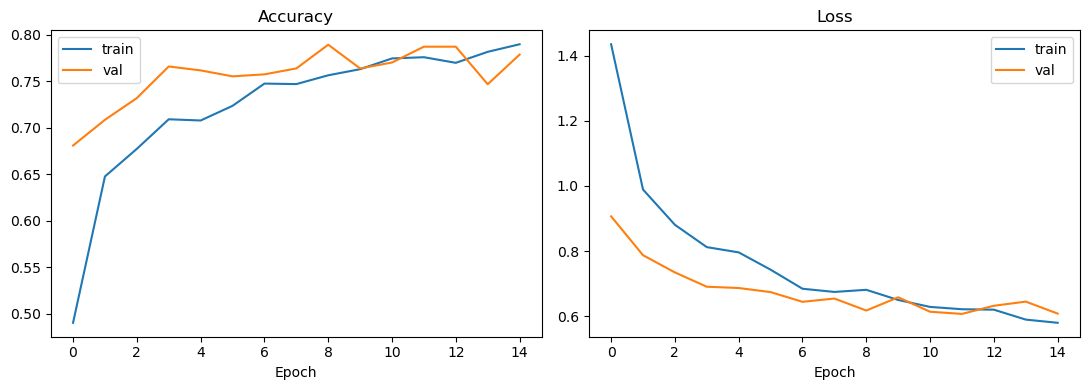

In [26]:
def plot_history(h):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h.history['accuracy'], label='train'); ax[0].plot(h.history['val_accuracy'], label='val')
    ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='train'); ax[1].plot(h.history['val_loss'], label='val')
    ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history)

15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 387ms/step
Test accuracy: 0.8083  (480 images)

                     precision    recall  f1-score   support

          Cardboard      0.725     0.860     0.787        43
      Food Organics      0.917     0.892     0.904        37
              Glass      0.732     0.769     0.750        39
              Metal      0.879     0.870     0.874        92
Miscellaneous Trash      0.737     0.500     0.596        56
              Paper      0.806     0.900     0.850        60
            Plastic      0.783     0.793     0.788        82
      Textile Trash      0.775     0.795     0.785        39
         Vegetation      0.909     0.938     0.923        32

           accuracy                          0.808       480
          macro avg      0.807     0.813     0.806       480
       weighted avg      0.808     0.808     0.804       480



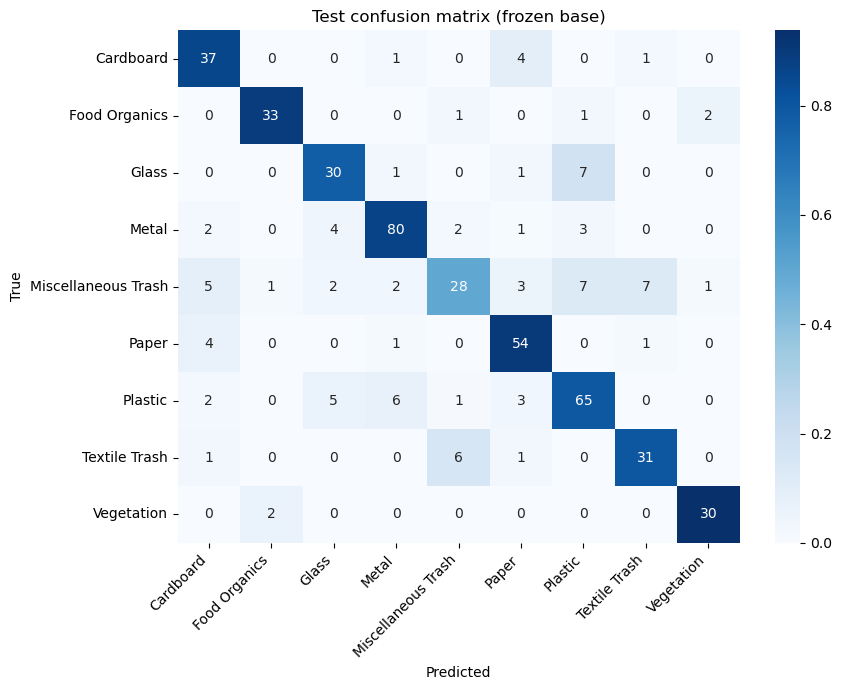

Top confusions (true -> predicted):
                 Glass -> Plastic              7
   Miscellaneous Trash -> Plastic              7
   Miscellaneous Trash -> Textile Trash        7
               Plastic -> Metal                6
         Textile Trash -> Miscellaneous Trash  6
   Miscellaneous Trash -> Cardboard            5
               Plastic -> Glass                5
             Cardboard -> Paper                4


In [27]:
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

model.save('cnn_phase1_frozen.keras')

from sklearn.metrics import confusion_matrix, classification_report

# test_dataset was built from a fixed in-memory list (no reshuffling),
# so predictions line up with labels in the same order
probs = model.predict(test_dataset)
y_pred = probs.argmax(axis=1)
y_true = np.concatenate([y.numpy().argmax(axis=1) for _, y in test_dataset])

phase1_test_acc = (y_pred == y_true).mean()
print(f"Test accuracy: {phase1_test_acc:.4f}  ({len(y_true)} images)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Confusion matrix: colour = share of each true class, numbers = raw counts
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=cm, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Test confusion matrix (frozen base)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

# Most common mistakes
off_diag = [(class_names[i], class_names[j], cm[i, j])
            for i in range(num_classes) for j in range(num_classes)
            if i != j and cm[i, j] > 0]
print("Top confusions (true -> predicted):")
for t, p, n in sorted(off_diag, key=lambda r: -r[2])[:8]:
    print(f"  {t:>20s} -> {p:<20s} {n}")

### 2.4 Fine-tune the Model

Base layers: 154 | trainable in base: 30
Epoch 1/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 77s 590ms/step - accuracy: 0.6875 - loss: 0.8745 - val_accuracy: 0.7809 - val_loss: 0.6468
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 72s 601ms/step - accuracy: 0.7491 - loss: 0.6972 - val_accuracy: 0.7574 - val_loss: 0.6751
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 73s 610ms/step - accuracy: 0.7667 - loss: 0.6329 - val_accuracy: 0.7617 - val_loss: 0.6815


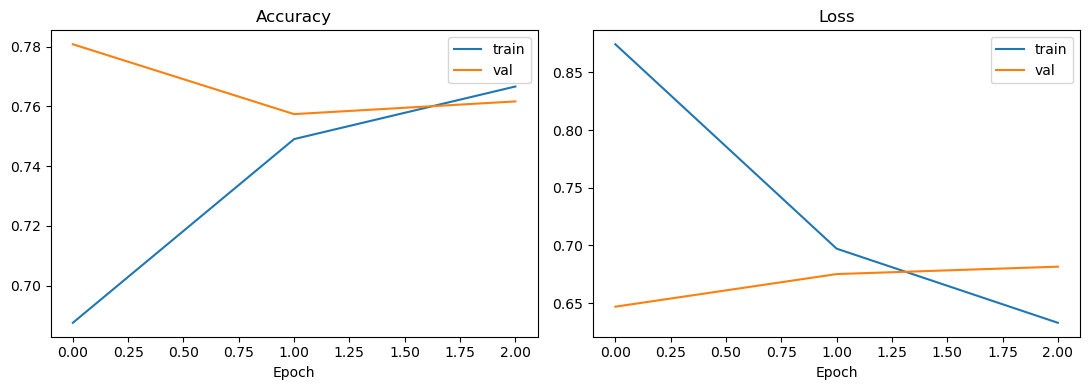

In [28]:
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Phase 2: unfreeze the last 30 layers of the base (roughly its final few blocks)
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
print("Base layers:", len(base_model.layers),
      "| trainable in base:", sum(l.trainable for l in base_model.layers))

# Recompiling is REQUIRED after changing trainable. Low learning rate (3e-5) so the
# pretrained features are nudged, not overwritten.
model.compile(optimizer=keras.optimizers.Adam(3e-5),
              loss='categorical_crossentropy', metrics=['accuracy'])

history_ft = model.fit(train_ds, validation_data=validation_ds, epochs=10,
                       class_weight=class_weight, callbacks=[early_stop])
plot_history(history_ft)
model.save('cnn_phase2_finetuned.keras')

Test confusion matrix (fine-tuned): test accuracy 0.8104

                     precision    recall  f1-score   support

          Cardboard      0.661     0.907     0.765        43
      Food Organics      0.895     0.919     0.907        37
              Glass      0.696     0.821     0.753        39
              Metal      0.882     0.815     0.847        92
Miscellaneous Trash      0.756     0.554     0.639        56
              Paper      0.839     0.867     0.852        60
            Plastic      0.829     0.768     0.797        82
      Textile Trash      0.821     0.821     0.821        39
         Vegetation      0.912     0.969     0.939        32

           accuracy                          0.810       480
          macro avg      0.810     0.827     0.813       480
       weighted avg      0.816     0.810     0.809       480



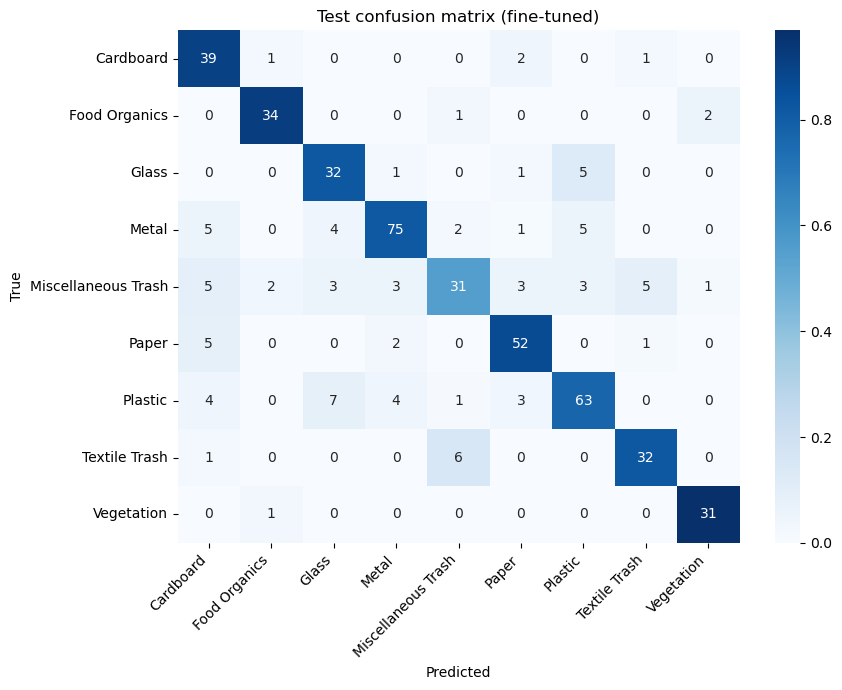

In [29]:
def evaluate_cnn(m, title):
    probs = m.predict(test_dataset, verbose=0)
    y_pred = probs.argmax(axis=1)
    y_true = np.concatenate([y.numpy().argmax(axis=1) for _, y in test_dataset])
    acc = (y_pred == y_true).mean()
    print(f"{title}: test accuracy {acc:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(title)
    plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()
    return acc, y_true, y_pred

ft_acc, y_true_ft, y_pred_ft = evaluate_cnn(model, 'Test confusion matrix (fine-tuned)')

**Fine-tuning experiment.** I unfroze the last 30 of 154 base layers and trained with Adam (lr 3e-5), class weights, and early stopping. Test accuracy was 81.0% vs. 80.8% for the frozen-base model (one image out of 480, within the ~1.8-point standard error); macro F1 was 0.813 vs. 0.806. On the validation set, which I use for model selection, fine-tuning did not improve: best validation loss 0.647 vs. 0.607, validation accuracy 78.1% vs. ~78.7%. Training loss kept falling (0.87 → 0.63) while validation loss rose (0.647 → 0.682) across three epochs, so overfitting began after one epoch of fine-tuning. Per-class changes (e.g., Miscellaneous Trash recall 0.50 → 0.55, Cardboard precision 0.73 → 0.66) amount to a few images each and are within noise. **Decision:** keep the frozen-base model, which is simpler and equal or better on validation, for the integrated assistant. **Limitations:** only one fine-tuning configuration was tried; a lower learning rate, fewer unfrozen layers, or stronger augmentation were not tested because of CPU training time (~75 s per epoch).

Reloaded model [loss, accuracy] on test: [0.5807825326919556, 0.8083333373069763]
92 misclassified of 480


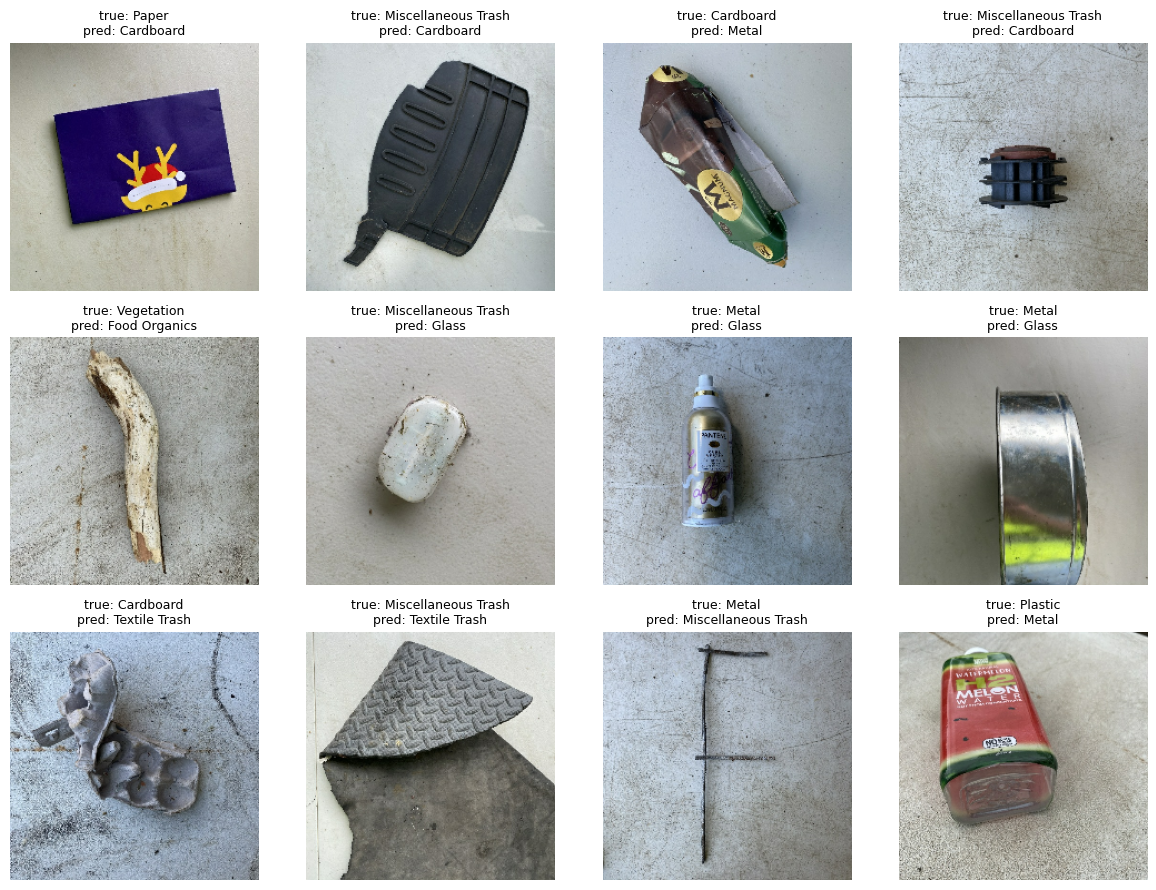

In [30]:
# Final CNN = frozen-base model (selected on validation performance, not test)
cnn_model = keras.models.load_model('cnn_phase1_frozen.keras')
print("Reloaded model [loss, accuracy] on test:", cnn_model.evaluate(test_dataset, verbose=0))  # accuracy should be ~0.808

y_pred_final = cnn_model.predict(test_dataset, verbose=0).argmax(axis=1)
y_true_final = np.concatenate([y.numpy().argmax(axis=1) for _, y in test_dataset])

# Look at actual mistakes (12 random misclassified test images)
test_images = np.concatenate([x.numpy() for x, _ in test_dataset]).astype('uint8')
wrong = np.where(y_true_final != y_pred_final)[0]
print(f"{len(wrong)} misclassified of {len(y_true_final)}")
show = np.random.RandomState(42).choice(wrong, size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx in zip(axes.ravel(), show):
    ax.imshow(test_images[idx]); ax.axis('off')
    ax.set_title(f"true: {class_names[y_true_final[idx]]}\npred: {class_names[y_pred_final[idx]]}", fontsize=9)
plt.tight_layout(); plt.show()

**Error analysis (final frozen-base model, 92 of 480 test images misclassified).** Inspecting 12 random errors shows three patterns. (1) *Ambiguous or defensible labels*: colored card stock labeled Paper but predicted Cardboard, a pale branch resembling food bone, molded-pulp egg cartons resembling fabric, and miscellaneous black rubber/plastic parts with no coherent identity, so part of the error ceiling is label ambiguity rather than model weakness. (2) *Material confusion on reflective or transparent surfaces*: shiny tins and an aerosol can predicted as Glass, and foil-printed packaging predicted as Metal; the model appears to rely on surface appearance and texture more than object function (e.g., a diamond-plate rubber mat predicted as Textile Trash). (3) *Small or thin objects* (a black stick) occupy few pixels after downscaling to 224×224. A few errors (e.g., a plastic bottle predicted as Metal) look like genuine model mistakes. Miscellaneous Trash and Metal account for 7 of the 12 sampled errors, consistent with the per-class results. Caveat: this is a qualitative sample of 12 images, not a systematic audit.

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [31]:
# - Apply the text preprocessing pipeline created earlier

# Show what the pipeline produced
print(train_text[['description', 'text', 'category']].head(8).to_string(index=False))
print("\nSplit sizes (train/val/test):", len(train_text), len(val_text), len(test_text))
print("Feature matrix:", X_train.shape, "| avg non-zero features per description:",
      round(X_train.getnnz(axis=1).mean(), 1))

                                                       description                                                               text            category
                                          ripped small paper towel                                           ripped small paper towel               Paper
                           small white Eco-Friendly food container                            small white eco-friendly food container             Plastic
                                ripped spotted wooden Local pencil                                 ripped spotted wooden local pencil Miscellaneous Trash
                                     stained large red orange peel                                      stained large red orange peel       Food Organics
                                                 dry packaging box                                                  dry packaging box           Cardboard
                                          ripped gold wool sweater          

**Pipeline output.** The 1.3 pipeline lowercases and whitespace-normalizes each description, then represents it as TF-IDF unigrams and bigrams (2,640 features; ~8 non-zero per description). I use sparse TF-IDF rather than dense embeddings because Option A is a traditional model and the vocabulary is tiny (305 words). The examples show the data-specific challenge: generated descriptions combine informative object/material nouns ("sweater", "pencil", "metal bottle") with noise modifiers ("Eco-Friendly", "Artisanal", "Brand A", "travel-sized") and condition words ("ripped", "stained", "dry") that appear across all categories. TF-IDF weighting plus a linear model lets the classifier learn which tokens carry the label without hand-crafted stop-word lists.

### 3.2 Implement Text Classification Model

In [32]:
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Candidate models, each with a couple of settings. Selection uses VALIDATION only.
candidates = {
    'NaiveBayes (alpha=0.1)': MultinomialNB(alpha=0.1),
    'NaiveBayes (alpha=1.0)': MultinomialNB(alpha=1.0),
    'LogReg (C=1)': LogisticRegression(C=1, max_iter=1000),
    'LogReg (C=10)': LogisticRegression(C=10, max_iter=1000),
    'LogReg (C=100)': LogisticRegression(C=100, max_iter=1000),
    'RandomForest (300 trees)': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

rows = []
for name, clf in candidates.items():
    clf.fit(X_train, y_train)
    p = clf.predict(X_val)
    rows.append({'model': name,
                 'val_acc': accuracy_score(y_val, p),
                 'val_macro_f1': f1_score(y_val, p, average='macro')})

results = pd.DataFrame(rows).sort_values('val_acc', ascending=False).round(4)
print(results.to_string(index=False))

                   model  val_acc  val_macro_f1
           LogReg (C=10)   0.9980        0.9979
          LogReg (C=100)   0.9960        0.9959
  NaiveBayes (alpha=1.0)   0.9919        0.9920
            LogReg (C=1)   0.9879        0.9880
  NaiveBayes (alpha=0.1)   0.9838        0.9842
RandomForest (300 trees)   0.9676        0.9676


**Model selection (validation set).** Six configurations were compared: Naive Bayes (alpha 0.1, 1.0), logistic regression (C = 1, 10, 100), and a 300-tree random forest. Validation accuracy: LogReg C=10 99.8%, LogReg C=100 99.6%, NB alpha=1 99.2%, LogReg C=1 98.8%, NB alpha=0.1 98.4%, random forest 96.8%. The top three differ by 1–4 of 494 validation descriptions, which is within noise; the random forest is clearly weaker (16 errors). I selected **logistic regression, C=10**: best on validation, it provides class probabilities (used as the confidence score in the integrated assistant), and its coefficients are interpretable. Regularization strength mattered modestly: C=10 beat both stronger (C=1) and weaker (C=100) regularization.

### 3.3 Train and Evaluate the Model

Test accuracy: 0.9980  (494 descriptions)

                     precision    recall  f1-score   support

          Cardboard      1.000     1.000     1.000        58
      Food Organics      1.000     1.000     1.000        51
              Glass      0.982     1.000     0.991        54
              Metal      1.000     1.000     1.000        51
Miscellaneous Trash      1.000     0.983     0.991        58
              Paper      1.000     1.000     1.000        49
            Plastic      1.000     1.000     1.000        56
      Textile Trash      1.000     1.000     1.000        58
         Vegetation      1.000     1.000     1.000        59

           accuracy                          0.998       494
          macro avg      0.998     0.998     0.998       494
       weighted avg      0.998     0.998     0.998       494



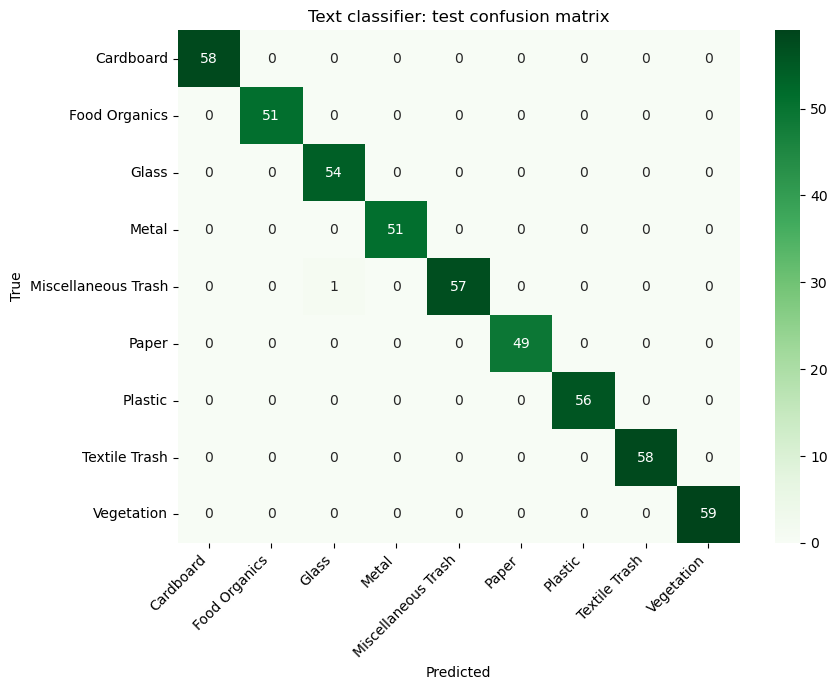

1 misclassified test descriptions
                    description            category  pred
mini glass Eco-Friendly battery Miscellaneous Trash Glass

Top features per class:
  Cardboard            box, cardboard, food packaging, packaging, egg carton, carton
  Food Organics        bread, peel, shells, scraps, bones, vegetable waste
  Glass                glass, bottle, light bulb, light, bulb, perfume bottle
  Metal                metal, nail, can, steel, wire, tin
  Miscellaneous Trash  tape, styrofoam, pencil, tool, battery, pen
  Paper                paper, notebook, envelope, newspaper, flyer, brochure
  Plastic              plastic, toothbrush, container, bottle, cd case, wrap
  Textile Trash        scarf, hat, gloves, curtain, rug, tablecloth
  Vegetation           plant, leaves, weeds, branches, houseplant, flowers


In [33]:
# - Use appropriate training parameters
# - Monitor training progress

from sklearn.metrics import classification_report, confusion_matrix

final_text_model = candidates['LogReg (C=10)']   # best on validation (already fitted on train in 3.2)

pred_test = final_text_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, pred_test):.4f}  ({len(y_test)} descriptions)\n")
print(classification_report(y_test, pred_test, target_names=class_names, digits=3))

cm_text = confusion_matrix(y_test, pred_test)
plt.figure(figsize=(9, 7))
sns.heatmap(cm_text, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Text classifier: test confusion matrix')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

# Every misclassified test description
errs = test_text.assign(pred=[class_names[i] for i in pred_test])
errs = errs[errs['pred'] != errs['category']]
print(f"{len(errs)} misclassified test descriptions")
if len(errs):
    print(errs[['description', 'category', 'pred']].to_string(index=False))

# What the model relies on: top-weighted features per class
feat = np.array(tfidf.get_feature_names_out())
print("\nTop features per class:")
for i, name in enumerate(class_names):
    top = feat[np.argsort(final_text_model.coef_[i])[-6:][::-1]]
    print(f"  {name:20s} {', '.join(top)}")

**Results.** Test accuracy 99.8% (493 of 494), macro F1 0.998, matching validation; every class has precision and recall ≥ 0.98. The single error is "mini glass Eco-Friendly battery" (true: Miscellaneous Trash, predicted: Glass): it contains a Glass keyword ("glass") and a Miscellaneous object ("battery"); the label follows the object, but a bag-of-words model weights the stronger keyword, and "glass battery" is likely a generation artifact rather than a real item.

**What the model learned.** The top-weighted features per class are object and material nouns (Cardboard: box, carton, egg carton; Glass: glass, bottle, light bulb; Metal: metal, nail, can, wire; Textile Trash: scarf, hat, curtain, rug; Vegetation: plant, leaves, weeds). None of the noise modifiers ("Eco-Friendly", "Artisanal", "Brand A") or condition words ("ripped", "stained") appear, so the model ignores them as intended. "bottle" is a top feature for both Glass and Plastic, mirroring the Glass↔Plastic confusion seen in the image model.

**Caveats.** The near-perfect score mostly reflects an easy task: a 305-word template vocabulary in which the label is determined by an object noun. It says little about real resident phrasing (tested below). The two datasets also label some items differently: the text data's top Plastic features include "toothbrush", whereas a RealWaste sample image shows a toothbrush under Miscellaneous Trash, so for the same item the image and text pathways can disagree.

In [34]:
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Robustness: swap two adjacent letters in one random word per test description
def add_typo(s, rng):
    words = s.split()
    i = rng.randrange(len(words)); w = words[i]
    if len(w) > 3:
        j = rng.randrange(len(w) - 1)
        w = w[:j] + w[j + 1] + w[j] + w[j + 2:]
    words[i] = w
    return ' '.join(words)

rng = random.Random(42)
typo_texts = [add_typo(t, rng) for t in test_text['text']]
typo_acc = accuracy_score(y_test, final_text_model.predict(tfidf.transform(typo_texts)))
print(f"Accuracy with one swapped-letter typo per description: {typo_acc:.4f}")

Accuracy with one swapped-letter typo per description: 0.9109


**Robustness.** To probe beyond the near-perfect test score, one random word per test description had two adjacent letters swapped. Accuracy fell from 99.8% to 91.1% (−8.7 points): a word-level TF-IDF vocabulary cannot recognize a misspelled object noun, so the model loses its main signal. Character n-gram features would likely be more typo-tolerant (not tested here).

### 3.4 Create Classification Function

In [36]:
# Create a function that takes a text description and returns the predicted waste category

def clean_text(s):
    """Same normalization as the training pipeline (lowercase, collapse whitespace)."""
    return re.sub(r'\s+', ' ', s.lower()).strip()

def classify_waste_description(description, return_confidence=False):
    """
    Classifies a waste description into one of the 9 categories.

    Args:
        description (str): Text description of waste item
        return_confidence (bool): also return the model's probability for the prediction

    Returns:
        str (or (str, float)): predicted category (and confidence).
        If the text contains no word the model knows, returns None (confidence 0.0)
        instead of guessing.
    """
    x = tfidf.transform([clean_text(description)])
    if x.nnz == 0:
        return (None, 0.0) if return_confidence else None
    probs = final_text_model.predict_proba(x)[0]
    best = int(probs.argmax())
    return (class_names[best], float(probs[best])) if return_confidence else class_names[best]

# Try it on phrasing that is NOT in the generated dataset's style
challenge = ["old pizza box with grease on it", "soda can", "broken glass jar",
             "banana peel", "bottle", "something broken", "asdfgh", ""]
for d in challenge:
    cat, conf = classify_waste_description(d, return_confidence=True)
    print(f"{d!r:36s} -> {cat}  ({conf:.2f})")

'old pizza box with grease on it'    -> Cardboard  (0.99)
'soda can'                           -> Metal  (1.00)
'broken glass jar'                   -> Glass  (0.99)
'banana peel'                        -> Food Organics  (1.00)
'bottle'                             -> Glass  (0.86)
'something broken'                   -> Textile Trash  (0.18)
'asdfgh'                             -> None  (0.00)
''                                   -> None  (0.00)


**Classification function.** `classify_waste_description` applies the same normalization as training and returns the category, optionally with the model's probability. On phrasing outside the dataset's style, results were sensible: "old pizza box with grease on it" → Cardboard (0.99), "soda can" → Metal (1.00), "broken glass jar" → Glass (0.99), "banana peel" → Food Organics (1.00). Vague or ambiguous input is the weak spot: "bottle" → Glass (0.86) even though "bottle" is a top feature for both Glass and Plastic (confidence overstated for an ambiguous word), and "something broken" → Textile Trash at only 0.18 confidence. Input with no known vocabulary ("asdfgh", empty string) returns `None` instead of a guess. In the integrated assistant (Part 5), a confidence threshold will route low-confidence text to a "not sure" response; a threshold cannot catch confident-but-ambiguous cases such as "bottle".

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [37]:
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

from sentence_transformers import SentenceTransformer

# Small (22M-parameter) sentence embedding model; downloads once from the Hugging Face hub
embedder = SentenceTransformer('all-MiniLM-L6-v2')

# Embed every chunk from rag_df (built in 1.3). With only 76 chunks, a normalized
# matrix + dot product IS the index: cosine similarity = embeddings @ query.
chunk_emb = embedder.encode(rag_df['text'].tolist(), normalize_embeddings=True,
                            show_progress_bar=False)
print("Chunk embeddings:", chunk_emb.shape)

def retrieve(query, k=4, category=None, exclude_sections=('Benefits',)):
    """Top-k chunks by cosine similarity. If `category` is given, only chunks about that
    category (plus 'General' ones) are searched. 'Benefits' sections are skipped by default."""
    q = embedder.encode([query], normalize_embeddings=True)[0]
    scores = chunk_emb @ q
    mask = ~rag_df['section'].isin(exclude_sections).values
    if category is not None:
        mask &= rag_df['category'].isin([category, 'General']).values
    idx = np.where(mask)[0]
    top = idx[np.argsort(-scores[idx])[:k]]
    return rag_df.iloc[top].assign(score=scores[top])

# Qualitative check
for _, r in retrieve("How to recycle Plastic", k=4, category='Plastic').iterrows():
    print(f"[{r['score']:.2f}] {r['category']} | {r['policy_type']} | {r['section']}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Chunk embeddings: (76, 384)
[0.69] Plastic | Disposal instructions | Disposal tips
[0.64] Plastic | Plastic Recycling Guidelines | Preparation Instructions
[0.53] Plastic | Plastic Recycling Guidelines | Acceptable Items
[0.51] Plastic | Plastic Recycling Guidelines | Collection Method


In [38]:
# Precision@5: share of the top-5 chunks that are about the right category (or General).
# "pure" = semantic search over everything; "filtered" = restricted to the category.
rows = []
for cat in class_names:
    q = f"How to recycle {cat}"
    pure = retrieve(q, k=5, exclude_sections=())
    filt = retrieve(q, k=5, category=cat)
    rows.append({'category': cat,
                 'pure_semantic_p@5': pure['category'].isin([cat, 'General']).mean(),
                 'filtered_p@5': filt['category'].isin([cat, 'General']).mean()})
ret_eval = pd.DataFrame(rows)
print(ret_eval.round(2).to_string(index=False))
print("\nMean:", ret_eval[['pure_semantic_p@5', 'filtered_p@5']].mean().round(3).to_dict())

# Free-text query with no category supplied
for _, r in retrieve("can I put a greasy pizza box in the recycling?", k=3).iterrows():
    print(f"[{r['score']:.2f}] {r['category']} | {r['section']}")

           category  pure_semantic_p@5  filtered_p@5
          Cardboard                1.0           1.0
      Food Organics                1.0           1.0
              Glass                1.0           1.0
              Metal                0.8           1.0
Miscellaneous Trash                0.4           1.0
              Paper                1.0           1.0
            Plastic                0.6           1.0
      Textile Trash                1.0           1.0
         Vegetation                1.0           1.0

Mean: {'pure_semantic_p@5': 0.867, 'filtered_p@5': 1.0}
[0.57] Cardboard | Disposal tips
[0.54] Cardboard | CARDBOARD GUIDELINES
[0.54] Cardboard | Acceptable Items


**Embeddings and index.** Each of the 76 chunks is embedded with `all-MiniLM-L6-v2` (384 dimensions, normalized). The index is the embedding matrix itself: with only 76 chunks, cosine similarity as one matrix–vector product is exact and instantaneous, so a vector database such as FAISS would add complexity without benefit.

**Retrieval design.** Queries have the form "How to recycle {category}" and the category is known from the classifiers, so retrieval is restricted to chunks tagged with that category or `General`, and `Benefits` sections (no actionable instructions) are excluded. Evidence for the filter: unrestricted semantic search averages precision@5 of 0.87 (right category, counting General chunks as correct), with failures concentrated in Miscellaneous Trash (0.4), Plastic (0.6), and Metal (0.8). Filtering gives 1.0 by construction, so it is a design choice justified by the unrestricted failures, not an accomplishment. Free-text queries still work without the filter: "can I put a greasy pizza box in the recycling?" retrieved only Cardboard chunks. Caveat: only 9 templated queries were evaluated. I use k=5 for generation so that "Non-Acceptable Items" sections are not crowded out.

### 4.2 Implement RAG-based System

In [39]:
# - Choose an appropriate language model
# - Create a retrieval mechanism

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

def build_prompt(category, k=5):
    """RAG prompt: retrieved policy chunks + the question the model must answer."""
    query = f"How to recycle {category}"
    ctx = retrieve(query, k=k, category=category)
    context_text = "\n\n".join(ctx['text'])
    return f"Context:\n{context_text}\n\nQuestion: {query}?\nAnswer:", ctx

gen_tokenizer = AutoTokenizer.from_pretrained('gpt2')
gen_tokenizer.pad_token = gen_tokenizer.eos_token
base_lm = AutoModelForCausalLM.from_pretrained('gpt2')   # pretrained, NOT fine-tuned yet

def generate_text(lm, prompt, max_new_tokens=120, **gen_kwargs):
    inputs = gen_tokenizer(prompt, return_tensors='pt')
    n_prompt = inputs['input_ids'].shape[1]
    assert n_prompt + max_new_tokens <= 1024, f"Prompt too long: {n_prompt} tokens"
    with torch.no_grad():
        out = lm.generate(**inputs, max_new_tokens=max_new_tokens,
                          pad_token_id=gen_tokenizer.eos_token_id, **gen_kwargs)
    return gen_tokenizer.decode(out[0][n_prompt:], skip_special_tokens=True).strip()

torch.manual_seed(42)
for cat in ['Glass', 'Textile Trash']:
    prompt, ctx = build_prompt(cat)
    print(f"=== {cat} | prompt tokens: {len(gen_tokenizer(prompt)['input_ids'])} ===")
    print(generate_text(base_lm, prompt, do_sample=True, temperature=0.7, top_p=0.9))
    print()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

=== Glass | prompt tokens: 215 ===
Glass recycling is a process that involves removing the glass from a glass box and then placing it in a glass recycling bin.

Glass recycling bin is an area of the recycling bin that is usually marked with a number. These numbers are used to determine the color of the glass and can be used to indicate the types of glass used. Glass recycling bins are usually located on a side of the main main building, usually in the front yard, and are usually used to collect the glass.

Glass recycling bin can be done by hand, but is also a lot easier if you have a glass box

=== Textile Trash | prompt tokens: 258 ===
- Cut materials from scrap metal and other non-textile materials.

- Use a dry cloth to clean up.

- Use a wet cloth for cleaning clothes.

- Use a dry cloth for washing, or a towel for dry cleaning.

- Wash clothes at a laundromat.

- Wash with soap or water.

- Wash with water.

- Wash with soap or water.

- Wash with soap or water.

- Wash with soap

**Baseline (no fine-tuning).** With the retrieved policy chunks in the prompt (215–258 tokens), pretrained GPT-2 imitates the *format* of the context but not its *content*. For Glass it produces fluent but invented statements (bins "marked with a number", "located in the front yard") and omits the documented advice; for Textile Trash it copies the bullet style, invents steps ("wash clothes at a laundromat"), contradicts the policy (textiles should go to textile bins or donation, clean and dry), and degenerates into repetition. This is the problem fine-tuning has to fix: the model must learn to take its facts from the retrieved text.

In [40]:
SECTION_LABEL = {
    'Acceptable Items': 'Accepted',
    'Non-Acceptable Items': 'Not accepted',
    'Items That Cannot Be Recycled': 'Not accepted',
    'Preparation Instructions': 'Prepare',
    'Collection Method': 'Collection',
    'Disposal tips': 'Tips',
    'Special Handling Items': 'Special handling',
    'Waste Reduction Tips': 'Reduce waste',
    'GENERAL REQUIREMENTS': 'General rules',
}

def chunk_lines(text):
    """Lines of a chunk after its title line, without bullets or trailing periods."""
    lines = [l.strip() for l in text.split('\n')[1:] if l.strip()]
    return [(l[2:] if l.startswith('- ') else l).strip().rstrip('.') for l in lines]

def build_target(category, chunks, n_items=3):
    """Instruction text built ONLY from the retrieved chunks (grounded by construction)."""
    parts = [f"To recycle {category}:"]
    for _, ch in chunks.iterrows():
        default = 'City guidelines' if ch['section'].endswith('GUIDELINES') else ch['section']
        label = SECTION_LABEL.get(ch['section'], default)
        parts.append(f"- {label}: " + "; ".join(chunk_lines(ch['text'])[:n_items]))
    return "\n".join(parts)

def make_prompt(query, chunks):
    return "Context:\n" + "\n\n".join(chunks['text']) + f"\n\nQuestion: {query}\nAnswer:"

QUERY_TEMPLATES = ["How to recycle {c}?", "How do I dispose of {c}?",
                   "What are the recycling rules for {c}?"]

pairs = []
for cat in class_names:
    for tmpl in QUERY_TEMPLATES:
        query = tmpl.format(c=cat)
        for k in (4, 5, 6):
            chunks = retrieve(query, k=k, category=cat)
            for seed in (None, 1):                      # original order, and one shuffled order
                ch = chunks if seed is None else chunks.sample(frac=1, random_state=seed)
                pairs.append({'category': cat,
                              'prompt': make_prompt(query, ch),
                              'target': build_target(cat, ch)})

pairs_df = pd.DataFrame(pairs).drop_duplicates('prompt').reset_index(drop=True)

# Hold out 2 variants per category for validation loss
val_idx = pairs_df.groupby('category').sample(n=2, random_state=42).index
pairs_val = pairs_df.loc[val_idx]
pairs_train = pairs_df.drop(val_idx)
print(f"Pairs: {len(pairs_df)} total | {len(pairs_train)} train | {len(pairs_val)} val")

# Token budget (GPT-2 window = 1024)
lens = [len(gen_tokenizer(p + ' ' + t)['input_ids']) for p, t in zip(pairs_df['prompt'], pairs_df['target'])]
print(pd.Series(lens).describe().round(0))

# Look at one full example
ex = pairs_train[pairs_train['category'] == 'Plastic'].iloc[0]
print("\n" + ex['prompt'])
print(ex['target'])

Pairs: 162 total | 144 train | 18 val
count    162.0
mean     360.0
std       66.0
min      234.0
25%      304.0
50%      353.0
75%      410.0
max      501.0
dtype: float64

Context:
Disposal instructions for Plastic:
- Remove labels if possible.
- Plastic bags can be returned to supermarket collection points.
- Rinse container before recycling.
- If unmarked or non-recyclable plastic, place in general waste.
- Check recycling number on bottom and sort accordingly.

Plastic Recycling Guidelines - Preparation Instructions
- Rinse containers
- Remove lids and caps (recycle separately)
- Check for recycling codes (1-7)

Plastic Recycling Guidelines - Acceptable Items
- PET bottles and containers (code #1)
- HDPE containers (code #2)
- PP containers (code #5)
- Clean plastic packaging

Plastic Recycling Guidelines - Collection Method
Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted.

Question: How to recycle Plastic?
Answer:
To recycle Plastic:


**Fine-tuning data.** The data has no human-written answers, so each training target is assembled from the retrieved chunks themselves: the first three items of each chunk, relabeled by section type (Accepted / Not accepted / Prepare / Collection / Tips; unlabeled city-wide guideline blocks get the neutral label "City guidelines"). Every target is therefore grounded in its context by construction; the model learns to condense and copy, not to write freely. Variety comes from three question phrasings, k = 4/5/6 retrieved chunks, and original vs. shuffled chunk order (the target follows the shuffled order, so positions cannot be memorized): 162 pairs (144 train / 18 validation; 234–501 tokens each, well inside GPT-2's 1,024-token window). 


**Limitations:** validation pairs come from the same documents as training pairs, so validation loss will be optimistic; truncating each chunk to three items drops information (e.g., for Plastic, the rule to put unmarked or non-recyclable plastic in general waste is cut); and k=4 prompts can omit the "Not accepted" section entirely.

### 4.3 Adjust and Evaluate the System

In [ ]:
# Train the RAG-based system
# - Adjust sampling methods/parameters

import time
from torch.utils.data import DataLoader

def encode_pair(prompt, target):
    p_ids = gen_tokenizer(prompt)['input_ids']
    t_ids = gen_tokenizer(' ' + target)['input_ids'] + [gen_tokenizer.eos_token_id]
    # labels = -100 on the prompt, so loss is computed on the answer tokens only
    return {'input_ids': p_ids + t_ids, 'labels': [-100] * len(p_ids) + t_ids}

def collate(batch):
    L = max(len(b['input_ids']) for b in batch)
    pad = gen_tokenizer.pad_token_id
    return {
        'input_ids': torch.tensor([b['input_ids'] + [pad] * (L - len(b['input_ids'])) for b in batch]),
        'attention_mask': torch.tensor([[1] * len(b['input_ids']) + [0] * (L - len(b['input_ids'])) for b in batch]),
        'labels': torch.tensor([b['labels'] + [-100] * (L - len(b['labels'])) for b in batch]),
    }

train_enc = [encode_pair(p, t) for p, t in zip(pairs_train['prompt'], pairs_train['target'])]
val_enc = [encode_pair(p, t) for p, t in zip(pairs_val['prompt'], pairs_val['target'])]
torch.manual_seed(42)
train_loader = DataLoader(train_enc, batch_size=4, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_enc, batch_size=4, shuffle=False, collate_fn=collate)

ft_lm = AutoModelForCausalLM.from_pretrained('gpt2')      # fresh copy; base_lm stays untouched for comparison
EPOCHS = 3
total_steps = EPOCHS * len(train_loader)
optimizer = torch.optim.AdamW(ft_lm.parameters(), lr=5e-5, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: max(0.0, 1 - s / total_steps))

def val_loss():
    ft_lm.eval(); total = 0.0
    with torch.no_grad():
        for b in val_loader:
            total += ft_lm(**b).loss.item() * b['input_ids'].shape[0]
    ft_lm.train()
    return total / len(val_enc)

history_lm = []
t0, step = time.time(), 0
ft_lm.train()
for epoch in range(EPOCHS):
    running = 0.0
    for b in train_loader:
        loss = ft_lm(**b).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(ft_lm.parameters(), 1.0)
        optimizer.step(); scheduler.step(); optimizer.zero_grad()
        running += loss.item(); step += 1
        if step <= 3 or step % 10 == 0:
            print(f"step {step}/{total_steps} | loss {loss.item():.3f} | {time.time() - t0:.0f}s elapsed")
    v = val_loss()
    history_lm.append({'epoch': epoch + 1, 'train_loss': running / len(train_loader), 'val_loss': v})
    print(f"== epoch {epoch + 1}: train {running / len(train_loader):.3f} | val {v:.3f}")

ft_lm.save_pretrained('gpt2_recycling_ft')
gen_tokenizer.save_pretrained('gpt2_recycling_ft')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


step 1/108 | loss 1.735 | 30s elapsed
step 2/108 | loss 1.441 | 44s elapsed
step 3/108 | loss 1.211 | 59s elapsed
step 10/108 | loss 0.621 | 133s elapsed
step 20/108 | loss 0.210 | 238s elapsed
step 30/108 | loss 0.110 | 335s elapsed
== epoch 1: train 0.472 | val 0.068
step 40/108 | loss 0.097 | 448s elapsed
step 50/108 | loss 0.083 | 548s elapsed
step 60/108 | loss 0.070 | 656s elapsed
step 70/108 | loss 0.061 | 767s elapsed
== epoch 2: train 0.076 | val 0.027
step 80/108 | loss 0.052 | 884s elapsed
step 90/108 | loss 0.027 | 983s elapsed
step 100/108 | loss 0.036 | 1088s elapsed
== epoch 3: train 0.039 | val 0.015


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('gpt2_recycling_ft/tokenizer_config.json', 'gpt2_recycling_ft/tokenizer.json')

**Fine-tuning.** GPT-2 (124M parameters) was fine-tuned on the 144 training pairs for 3 epochs (108 steps, batch size 4, AdamW, learning rate 5e-5 with linear decay, gradient clipping). Loss is computed only on answer tokens (prompt tokens are masked), and an end-of-text token is appended so the model learns to stop. Average training loss fell from 0.472 to 0.076 to 0.039 across epochs and validation loss from 0.068 to 0.027 to 0.015; training took about 19 minutes on CPU. Validation loss is optimistic because validation pairs share their source documents with training pairs, so it shows the format was learned, not that the model generalizes; the tests below address that.

In [42]:
# Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

torch.manual_seed(42)
for cat in ['Glass', 'Textile Trash']:
    prompt, ctx = build_prompt(cat)
    print(f"=== {cat} ===")
    print("[greedy]\n" + generate_text(ft_lm, prompt, max_new_tokens=200, do_sample=False))
    print("\n[sampled, T=0.7, top_p=0.9]\n" + generate_text(ft_lm, prompt, max_new_tokens=200,
                                                              do_sample=True, temperature=0.7, top_p=0.9))
    print()

=== Glass ===
[greedy]
To recycle Glass:
- Tips: Remove caps, lids, and corks before recycling; Rinse container before recycling; Place in glass recycling bin, sorted by color if required
- Prepare: Rinse containers; Remove caps and lids (recycle separately); Labels can remain
- Collection: Place in dedicated glass recycling bins. Some areas require color sorting
- Not accepted: Window glass or mirrors; Drinking glasses; Ceramics or pottery
- Accepted: Glass bottles (all colors); Glass jars; Glass food containers

[sampled, T=0.7, top_p=0.9]
To recycle Glass:
- Tips: Remove caps, lids, and corks before recycling; Rinse container; Place in glass recycling bin, sorted by color if required
- Prepare: Rinse containers; Remove caps and lids (recycle separately); Labels can remain
- Collection: Place in dedicated glass recycling bins. Some areas require color sorting
- Not accepted: Window glass or mirrors; Drinking glasses; Ceramics or pottery
- Accepted: Glass bottles (all colors); Glass j

In [43]:
# Context-reliance probe 1: change one rule in the retrieved text and see if the output follows it
prompt, ctx = build_prompt('Glass')
edited = prompt.replace("Remove caps, lids, and corks before recycling",
                        "Wrap the item in blue paper before recycling")
print("edit applied:", edited != prompt)

out_orig = generate_text(ft_lm, prompt, max_new_tokens=200, do_sample=False)
out_edit = generate_text(ft_lm, edited, max_new_tokens=200, do_sample=False)
print("original output mentions 'blue paper':", 'blue paper' in out_orig.lower())
print("edited output mentions 'blue paper':  ", 'blue paper' in out_edit.lower())
print("edited output still says 'remove caps, lids':", 'remove caps, lids' in out_edit.lower())
print("\n" + out_edit)

# Probe 2: ask about Glass but supply Textile Trash context
_, tex_ctx = build_prompt('Textile Trash')
swapped = make_prompt("How to recycle Glass?", tex_ctx)
print("\n[Glass question, Textile context]\n" + generate_text(ft_lm, swapped, max_new_tokens=200, do_sample=False))

edit applied: True
original output mentions 'blue paper': False
edited output mentions 'blue paper':   True
edited output still says 'remove caps, lids': False

To recycle Glass:
- Tips: Wrap the item in blue paper before recycling; Rinse container before recycling; Place in glass recycling bin, sorted by color if required
- Prepare: Rinse containers; Remove caps and lids (recycle separately); Labels can remain
- Collection: Place in dedicated glass recycling bins. Some areas require color sorting
- Not accepted: Window glass or mirrors; Drinking glasses; Ceramics or pottery
- Accepted: Glass bottles (all colors); Glass jars; Glass food containers

[Glass question, Textile context]
To recycle Glass:
- Tips: Look for textile recycling programs in your area; If no recycling options exist, place in general waste; Cut into rags for home use if appropriate
- Prepare: Ensure all items are clean and dry; Remove non-textile components when possible; Bag similar items together
- Collection: Pla

**Qualitative results and context-reliance tests.** Before fine-tuning, GPT-2 invented content. After fine-tuning, the Glass and Textile Trash outputs are condensed restatements of the retrieved policy text, with no repetition (Glass: remove caps, lids, and corks, rinse, color-sorted glass bins, window glass and ceramics not accepted; Textile Trash: textile bins or donation, clean and dry items, no carpets or wet or moldy textiles). Because these prompts likely match training prompts, I tested whether the model reads its context instead of memorizing. (1) Replacing one rule in the Glass context ("Remove caps, lids, and corks" → "Wrap the item in blue paper") made the output contain the new rule and drop the old one (the separate "Prepare: Remove caps and lids" line, from a different policy line, remained). (2) Supplying Textile Trash context under a Glass question produced textile advice under a "To recycle Glass" header. So the model follows the retrieved text rather than memorized category facts. This is good for faithfulness but risky: if retrieval returned the wrong category's chunks, the model would confidently output wrong-category advice (in the pipeline, category-filtered retrieval prevents this). Faithful is also not the same as correct: the Textile output reproduces the policy's own inconsistency (it lists "Clean clothing (all conditions)" as accepted but "Heavily soiled items" as not accepted).

In [44]:
def generate_with_context(category, k=5, lm=None, max_new_tokens=200, **gen_kwargs):
    """Retrieve policy chunks for `category`, then generate instructions grounded in them.
    Returns (instructions_text, retrieved_chunks). Greedy decoding unless sampling args are passed."""
    lm = lm or ft_lm
    prompt, ctx = build_prompt(category, k=k)
    gen_kwargs = gen_kwargs or {'do_sample': False}
    return generate_text(lm, prompt, max_new_tokens=max_new_tokens, **gen_kwargs), ctx

def grounded_fraction(generated, ctx):
    """Share of generated items (split on lines and ';') found verbatim in the retrieved text. Strict."""
    context_norm = ' '.join(ctx['text']).lower()
    items = []
    for line in generated.split('\n'):
        line = line.strip().lstrip('-').strip()
        if ':' in line:
            line = line.split(':', 1)[1]
        items += [s.strip().rstrip('.').lower() for s in line.split(';') if s.strip()]
    return sum(i in context_norm for i in items) / len(items) if items else 0.0

# Baseline GPT-2 vs fine-tuned GPT-2 on all 9 categories
rows = []
torch.manual_seed(42)
for cat in class_names:
    base_txt, ctx = generate_with_context(cat, lm=base_lm, max_new_tokens=120,
                                          do_sample=True, temperature=0.7, top_p=0.9)
    ft_txt, _ = generate_with_context(cat)
    rows.append({'category': cat,
                 'base_grounded': grounded_fraction(base_txt, ctx),
                 'ft_greedy_grounded': grounded_fraction(ft_txt, ctx)})
eval_df = pd.DataFrame(rows)
print(eval_df.round(2).to_string(index=False))
print("Mean:", eval_df[['base_grounded', 'ft_greedy_grounded']].mean().round(3).to_dict())
print("\nExample fine-tuned output (", class_names[-1], "):\n", ft_txt)

# Sampling comparison on 3 categories
sample_cats = ['Glass', 'Plastic', 'Textile Trash']
samp_rows = [{'setting': 'greedy',
              'mean_grounded': eval_df.set_index('category').loc[sample_cats, 'ft_greedy_grounded'].mean()}]
for name, kw in {'T=0.7, top_p=0.9': dict(do_sample=True, temperature=0.7, top_p=0.9),
                 'T=1.0, top_p=1.0': dict(do_sample=True, temperature=1.0, top_p=1.0)}.items():
    scores = []
    for cat in sample_cats:
        torch.manual_seed(42)
        txt, ctx = generate_with_context(cat, **kw)
        scores.append(grounded_fraction(txt, ctx))
    samp_rows.append({'setting': name, 'mean_grounded': np.mean(scores)})
print("\n", pd.DataFrame(samp_rows).round(3).to_string(index=False))

           category  base_grounded  ft_greedy_grounded
          Cardboard           0.71                1.00
      Food Organics           0.00                0.92
              Glass           0.67                1.00
              Metal           0.00                0.95
Miscellaneous Trash           0.00                0.84
              Paper           0.90                0.94
            Plastic           0.90                1.00
      Textile Trash           0.00                1.00
         Vegetation           0.83                1.00
Mean: {'base_grounded': 0.446, 'ft_greedy_grounded': 0.962}

Example fine-tuned output ( Vegetation ):
 To recycle Vegetation:
- Prepare: Cut branches to appropriate length (usually under 4 feet); Remove non-plant materials; Keep separate from other waste streams
- Not accepted: Soil or dirt; Rocks or gravel; Treated wood
- Collection: Use dedicated yard waste bins or paper yard waste bags
- Tips: Large branches may need to be cut to appropriate 

**Groundedness evaluation.** Metric: the share of generated items (split on lines and ";") that appear in the retrieved text (substring match). Across all 9 categories, mean groundedness rose from 0.45 (baseline GPT-2, sampled at T=0.7) to 0.96 (fine-tuned, greedy). Baseline scores were erratic (0.00 for Food Organics, Metal, Miscellaneous Trash, and Textile Trash; 0.67–0.90 for the rest) because the untrained model sometimes echoes context lines and sometimes invents content. Fine-tuned scores ranged from 0.84 to 1.00 (lowest: Miscellaneous Trash 0.84, Food Organics 0.92, Paper 0.94, Metal 0.95); the individual ungrounded items were not inspected. 


**Sampling:** greedy, T=0.7/top-p 0.9, and T=1.0 all scored 1.0 on Glass, Plastic, and Textile Trash. After fine-tuning the output distribution is so peaked that sampling parameters barely matter, so greedy decoding (deterministic and reproducible) is used. 


**Limitations:** substring matching counts truncated items as grounded and cannot detect omissions (e.g., a missing "Not accepted" line); echoing the context scores high even when unhelpful; the metric measures copy fidelity, not relevance or correctness; there is one generation per category and no repeated sampling; targets were built with the same copy-and-relabel rule the model was trained on; each chunk was truncated to three items; and there was no human evaluation of readability.

The metric also cannot detect a correctly copied item placed under the wrong label (seen in the Paper output in 5.3, where acceptable items appeared under "Not accepted").

### 4.4 Create Instruction Generation Function

In [45]:
# Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Retrieves the policy chunks for the category (k=5), builds a prompt from them,
    and generates the answer with the fine-tuned GPT-2 using greedy decoding.

    Args:
        waste_category (str): Waste category (one of the 9 class names)

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents (dicts with source, section, text)
    """
    if waste_category not in class_names:
        raise ValueError(f"Unknown waste category: {waste_category!r}. Expected one of {class_names}")
    instructions, ctx = generate_with_context(waste_category)
    docs = [{'source': r.policy_type, 'section': r.section, 'text': r.text} for r in ctx.itertuples()]
    return instructions, docs

# Quick check
instructions, docs = generate_recycling_instructions('Metal')
print(instructions)
print("\nPolicy documents used:", [f"{d['source']} / {d['section']}" for d in docs])

To recycle Metal:
- Tips: For aerosol cans, ensure they are completely empty and not pressurized; Ensure it is clean and empty before recycling; Place in metal recycling bin
- Prepare: Rinse containers to remove food residue; Crush cans if possible to save space; Remove non-metal metal components
- Collection: Place in recycling bins or take to metal recycling centers
- Not accepted: Containers with hazardous material; Pressurized containers; Electronics with metal parts
- Accepted: Aluminum cans; Steel food cans; Metal lids and bottle caps

Policy documents used: ['Disposal instructions / Disposal tips', 'Metal Recycling Guidelines / Preparation Instructions', 'Metal Recycling Guidelines / Collection Method', 'Metal Recycling Guidelines / Non-Acceptable Items', 'Metal Recycling Guidelines / Acceptable Items']


**Instruction generation function.** `generate_recycling_instructions(waste_category)` validates the category (raising a clear error for unknown names), retrieves the top-5 category-filtered policy chunks, builds the RAG prompt, and generates with the fine-tuned GPT-2 using greedy decoding (deterministic; sampling made no measurable difference after fine-tuning). It returns the instruction text and the retrieved policy documents (source, section, text), so every answer can be traced to its sources. Example (Metal): the output follows the Metal guidelines and disposal tips (aerosol cans must be empty, rinse and crush cans, no pressurized containers); it contains one odd phrase ("Remove non-metal metal components"), likely a copy slip that I did not check against the source wording.

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

**Architecture.** One entry point, `waste_management_assistant(input_data, input_type)`, routes the input through three components:

    image ──► CNN (MobileNetV2, frozen base) ─┐
                                              ├─► (category, confidence) ──► confidence gate (≥ 0.5)
    text ───► TF-IDF + logistic regression ───┘                                      │
                                                                                     ▼
                    category ──► retriever (MiniLM embeddings, category-filtered) ──► fine-tuned GPT-2
                                                                                     │
                                                       instructions + retrieved policy documents

Both classifiers return the same `(category, confidence)` pair over the same 9 labels (the text model reuses the image model's class order), so the generator does not care which path produced the category. Failures are caught at the entry point and returned as a message instead of an exception. Low-confidence predictions (< 0.5) are not passed to the generator: the assistant reports its best guess and asks for more detail instead.

In [46]:
# Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

CONF_THRESHOLD = 0.5   # below this, the assistant asks for more detail instead of guessing

def classify_image(img):
    """CNN interface. img: file path, PIL image, or HxWx3 array (0-255). Returns (category, confidence)."""
    if isinstance(img, (str, pathlib.Path)):
        img = Image.open(img)
    if isinstance(img, Image.Image):
        img = img.convert('RGB')
    arr = np.asarray(img, dtype=np.float32)
    if arr.ndim != 3 or arr.shape[-1] != 3:
        raise ValueError(f"Expected an HxWx3 image, got an array of shape {arr.shape}")
    arr = tf.image.resize(arr, (IMG_HEIGHT, IMG_WIDTH)).numpy()      # same resize as training
    probs = cnn_model.predict(arr[None, ...], verbose=0)[0]          # model expects raw 0-255 pixels
    best = int(probs.argmax())
    return class_names[best], float(probs[best])

# Component interfaces:
#   classify_image(img)                                      -> (category, confidence)   [CNN, Part 2]
#   classify_waste_description(text, return_confidence=True) -> (category, confidence)   [text model, Part 3]
#   generate_recycling_instructions(category)                -> (instructions, policy_docs)  [RAG, Part 4]
print(classify_image(test_images[0]), "| true:", class_names[y_true_final[0]])

('Miscellaneous Trash', 0.33549124002456665) | true: Miscellaneous Trash


### 5.2 Implement Integrated Assistant

In [47]:
# Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: input_type, category, confidence, instructions, policy_documents, message.
              If confidence is below CONF_THRESHOLD, instructions stay None and `message`
              explains why; invalid input never raises, it fills `message`.
    """
    result = {'input_type': input_type, 'category': None, 'confidence': None,
              'instructions': None, 'policy_documents': [], 'message': ''}
    try:
        if input_type == "image":
            category, conf = classify_image(input_data)
        elif input_type == "text":
            if not isinstance(input_data, str) or not input_data.strip():
                result['message'] = 'Please provide a non-empty description.'
                return result
            category, conf = classify_waste_description(input_data, return_confidence=True)
        else:
            result['message'] = f"Unknown input_type {input_type!r}; use 'image' or 'text'."
            return result

        result['confidence'] = round(conf, 3)
        if category is None:
            result['message'] = "I couldn't recognize any waste-related words in that description."
            return result
        result['category'] = category                      # keep the best guess visible
        if conf < CONF_THRESHOLD:
            result['message'] = (f"Not confident enough (best guess: {category}, {conf:.2f}). "
                                 "Please add detail or upload a clearer photo.")
            return result
        instructions, docs = generate_recycling_instructions(category)
        result.update(instructions=instructions, policy_documents=docs)
    except Exception as e:
        result['message'] = f"Could not process the input ({type(e).__name__}: {e})."
    return result

**Assistant implementation.** `waste_management_assistant(input_data, input_type)` returns a dictionary with `category`, `confidence`, `instructions`, `policy_documents`, and `message`. Flow: classify (CNN for images, TF-IDF + logistic regression for text) → confidence gate (≥ 0.5) → category-filtered retrieval → instruction generation. Design choices: (1) both classifiers return `(category, confidence)` over the same 9 labels, so the generator is independent of the input type; (2) below the threshold the best guess and confidence are returned without instructions, plus a message asking for more detail; (3) the entry point never raises: invalid input types, empty or non-string text, unreadable files, and wrongly shaped arrays all return an explanatory `message`; (4) the retrieved policy documents are returned with the instructions. The 0.5 threshold was chosen in advance, not tuned.

### 5.3 Evaluate the Integrated System

In [48]:
# Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

def show(res, true=None):
    print(f"[{res['input_type']}] category={res['category']} (true: {true}) confidence={res['confidence']}")
    if res['message']:
        print("  message:", res['message'])
    if res['instructions']:
        g = grounded_fraction(res['instructions'], pd.DataFrame(res['policy_documents']))
        print(res['instructions'])
        print(f"  grounded in retrieved docs: {g:.2f} | sources: " +
              '; '.join(f"{d['source']} / {d['section']}" for d in res['policy_documents']))
    print('-' * 70)

# 1) Images from the test set: one correctly classified, one misclassified
i_ok, i_bad = int(np.where(y_true_final == y_pred_final)[0][0]), int(wrong[0])
for i in (i_ok, i_bad):
    show(waste_management_assistant(test_images[i], "image"), true=class_names[y_true_final[i]])

# 2) Text descriptions from the test set
for _, row in test_text.sample(4, random_state=42).iterrows():
    show(waste_management_assistant(row['description'], "text"), true=row['category'])

# 3) Edge cases: ambiguous, vague, gibberish, empty, wrong types
for data, kind in [("bottle", "text"), ("something broken", "text"), ("asdfgh", "text"), ("", "text"),
                   (None, "text"), ("no_such_file.jpg", "image"), (np.zeros((5, 5)), "image"),
                   ("hello", "audio")]:
    print(f"### {kind}: {str(data)[:30]!r}")
    show(waste_management_assistant(data, kind))

# 4) Overall performance and the effect of the confidence threshold (test sets, no generation)
img_probs = cnn_model.predict(test_dataset, verbose=0)
txt_probs = final_text_model.predict_proba(X_test)
rows = []
for name, probs, y in [('image', img_probs, y_true_final), ('text', txt_probs, y_test)]:
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    for t in (0.0, 0.5, 0.7, 0.9):
        keep = conf >= t
        rows.append({'input': name, 'threshold': t, 'coverage': keep.mean(),
                     'accuracy_on_answered': (pred[keep] == y[keep]).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

[image] category=Miscellaneous Trash (true: Miscellaneous Trash) confidence=0.335
  message: Not confident enough (best guess: Miscellaneous Trash, 0.34). Please add detail or upload a clearer photo.
----------------------------------------------------------------------
[image] category=Food Organics (true: Vegetation) confidence=0.641
To recycle Food Organics:
- Prepare: Remove all packaging; Drain excess liquids; Use compostable bags if required
- Accepted: Fruit and vegetable scraps; Meat and fish (including bones); Dairy products
- Tips: If no compost available, place in general waste; Keep separate from recyclable materials; Use compostable bags for collection if required
- Collection: Use dedicated food waste bins lined with compostable bags
- City guidelines: Fruit and vegetable scraps; Meat and fish (including bones); Dairy products
- Tips: If no compost available, place in general waste; Use compostable bags for collection if required
- Collection: Use dedicated food waste bin

**Integrated system evaluation.**

*Image inputs.* A correctly classified test image (Miscellaneous Trash) was declined: the CNN was right but only 0.34 confident, so the assistant asked for a clearer photo. A misclassified image (true Vegetation, predicted Food Organics, confidence 0.64) passed the gate, and the assistant produced fluent, well-grounded instructions for the wrong category (meat, fish, and dairy as accepted items). The pipeline is faithful to the category it is given, not to the user's actual item.

*Text inputs.* Four random test descriptions were all classified correctly (Vegetation 0.89, Paper 0.79, Miscellaneous Trash 0.99 and 0.96); groundedness of the generated instructions was 0.92–1.00.

*Edge cases.* Gibberish ("asdfgh") returned "no recognizable words"; the vague "something broken" (0.18) was gated; empty and `None` text, a missing image file, a 2-D array, and an unknown input type all returned messages without raising. The ambiguous "bottle" was classified as Glass at 0.86 and passed the gate, so a confidence gate cannot catch confident-but-ambiguous input.

*Confidence threshold (test sets).* Image: answering everything gives 80.8% accuracy; at threshold 0.5 the assistant answers 89.0% of images at 85.5% accuracy, at 0.7 it answers 70.6% at 92.9%, and at 0.9 it answers 46.5% at 97.8%. Text: accuracy is 99.8% at every threshold up to 0.5, so the gate matters only for out-of-style input. The 0.5 threshold was not tuned; for images, 0.7 may be a better tradeoff (a product decision).

*Generation problems observed.* (1) Retrieved chunks from different documents can contain identical or overlapping text (two identical GENERAL REQUIREMENTS blocks; a Food Organics city-guideline block repeating the Accepted items), so outputs repeat lines; deduplicating retrieved chunks before prompting would fix this. (2) TThe Paper output listed items that the source chunk puts under “Acceptable Items” (office paper and mail, newspapers and magazines, books and catalogs) under “Not accepted”, and merged two lines into one. A user would have been told newspapers cannot be recycled. I confirmed this by checking the retrieved chunk. (3) One Miscellaneous Trash output mixed items across sections. The groundedness metric cannot see these errors, since it only checks that each item's text appears in the retrieved documents, not that it sits under the right label.

## Summary, limitations, and next steps

**What was built.** A CNN (MobileNetV2 transfer learning; 80.8% test accuracy on 9 classes), a TF-IDF + logistic regression text classifier (99.8% test accuracy; 91.1% under letter-swap typos), and a RAG generator (category-filtered MiniLM retrieval over 76 policy chunks plus GPT-2 fine-tuned to restate retrieved text; groundedness 0.96 vs. 0.45 for the untrained model), integrated behind one assistant with confidence gating and input-error handling.

**Key limitations.**
- *Data:* RealWaste floor color differs by class (possible shortcut); the text data is template-generated (near-ceiling accuracy, weak typo robustness); the image and text datasets label some items differently (e.g., toothbrush).
- *Image model:* one fine-tuning configuration was tried and did not beat the frozen base; Miscellaneous Trash is the weak class (recall 0.50); per-class test metrics are noisy (32–92 images per class).
- *Generator:* targets were assembled from the documents, so the model learned to condense and copy rather than write freely; chunks were truncated to three items; the policy documents contain inconsistencies (e.g., soiled textiles) that are reproduced faithfully; the groundedness metric cannot detect mislabeled sections or omissions; there was no human evaluation.
- *System:* the confidence threshold is untuned and cannot catch confident errors (Vegetation → Food Organics at 0.64; "bottle" → Glass at 0.86); no user-feedback mechanism was implemented; generation runs on CPU.

**Next steps.** Deduplicate retrieved chunks; check that each generated line sits under the label of its source section; test character n-gram features against typos; tune the threshold per input type; try other CNN fine-tuning settings; add a feedback mechanism.

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.